# Biomedical Image Processing & Analysis — HER Tutorial Notebook

## T1–T15 Integrated Practical

This notebook restructures the existing biomedical-image project into six tutorials:

- **T1:** Understanding HER / biomedical image dataset structure
- **T2:** Preprocessing — standardization and data cleaning
- **T3:** Preprocessing — redundant data removal and missing data
- **T4:** Biomedical image processing — enhancement, restoration, segmentation, compression
- **T5:** Biomedical image analysis — SIFT, RANSAC, CNN
- **T6:** Biomedical image visualization

The implementation is designed around the existing **BraTS-style multimodal brain MRI/NIfTI workflow** in the supplied project.

T7–T15 extend this original MRI notebook using shared offline analytics in `her_core.analytics`. The filename is retained for compatibility.


## 0. Setup

The notebook uses the existing project's Python workflow and adds the packages needed for the six tutorials.

If your environment does not contain one of these packages, install it with pip before running the corresponding section.

In [1]:
# Core numerical/data libraries
import os
import glob
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

# Biomedical image I/O
try:
    import nibabel as nib
except ImportError:
    nib = None

# Image processing
try:
    import cv2
except ImportError:
    cv2 = None

try:
    from skimage import exposure, filters, restoration, transform, feature, measure
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
except ImportError:
    exposure = filters = restoration = transform = feature = measure = None

# ML
try:
    from sklearn.model_selection import train_test_split
    from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
except ImportError:
    train_test_split = classification_report = confusion_matrix = accuracy_score = None


# Ensure the project root (with her_core/) is importable when the notebook
# is opened from this folder or from Downloads.
import sys
from pathlib import Path as _Path
_ROOT_CANDIDATES = [
    _Path.cwd(),
    _Path.cwd() / "HER_Biomedical_Image_Tutorials",
    *_Path.cwd().parents,
]
for _root in _ROOT_CANDIDATES:
    if (_root / "her_core").exists() and str(_root) not in sys.path:
        sys.path.insert(0, str(_root))
        print("Added to sys.path:", _root)
        break

print("Setup complete.")
print("Nibabel:", "available" if nib is not None else "not installed")
print("OpenCV:", "available" if cv2 is not None else "not installed")
print("scikit-image:", "available" if exposure is not None else "not installed")

Added to sys.path: C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials
Setup complete.
Nibabel: available
OpenCV: available
scikit-image: available


# T1 — Understanding HER / the Biomedical Image Data

## 1.1 What the project is working with

The supplied project uses a multimodal brain-MRI workflow. A patient/study can contain several MRI modalities, typically:

- **T1**
- **T1ce** — contrast-enhanced T1
- **T2**
- **FLAIR**
- **Segmentation mask**

The MRI scans are stored as **NIfTI volumes**, so a single file contains a 3-D image rather than one ordinary 2-D image.

The first step is therefore to understand the dataset structure before preprocessing it.

In [2]:
from her_core.io import default_data_root
DATA_ROOT = default_data_root()
print("Dataset root:", DATA_ROOT)
print("Present:", DATA_ROOT.exists())


Dataset root: C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020
Present: True


In [3]:
# Discover NIfTI files in the project/dataset.
nii_files = []
if DATA_ROOT.exists():
    nii_files = sorted(
        list(DATA_ROOT.rglob("*.nii")) +
        list(DATA_ROOT.rglob("*.nii.gz"))
    )

print("NIfTI files found:", len(nii_files))
for f in nii_files[:10]:
    print(f)

NIfTI files found: 34
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_001\BraTS20_Training_001_flair.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_001\BraTS20_Training_001_t2.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_002\BraTS20_Training_002_flair.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_002\BraTS20_Training_002_t2.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_206\BraTS20_Training_206_flair.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_206\BraTS20_Training_206_seg.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_206\BraTS20_Training_206_t1.nii.gz
C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020\BraTS20_Training_206\BraTS20_Training_206_t1ce.nii.gz
C:\Use

## 1.2 Inspect one MRI volume

NIfTI data are normally represented as:

`height × width × depth`

where `depth` corresponds to axial slices through the volume.

In [4]:
def load_nifti(path):
    if nib is None:
        raise ImportError("Install nibabel first: pip install nibabel")
    nii = nib.load(str(path))
    return nii.get_fdata(), nii

if nii_files and nib is not None:
    sample_volume, sample_nii = load_nifti(nii_files[0])
    print("Shape:", sample_volume.shape)
    print("Data type:", sample_volume.dtype)
    print("Minimum:", np.nanmin(sample_volume))
    print("Maximum:", np.nanmax(sample_volume))
else:
    print("Add the dataset path and make sure nibabel is installed.")

Shape:

 (224, 256, 224)
Data type: float64
Minimum: 0.0
Maximum: 1131.5389709472656


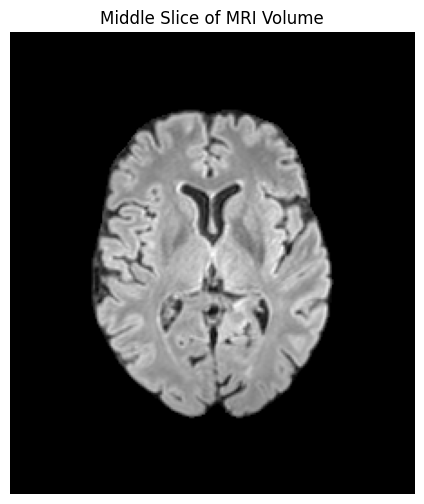

In [5]:
def middle_slice(volume):
    return volume[:, :, volume.shape[2] // 2]

if 'sample_volume' in globals():
    plt.figure(figsize=(6, 6))
    plt.imshow(middle_slice(sample_volume).T, cmap="gray", origin="lower")
    plt.title("Middle Slice of MRI Volume")
    plt.axis("off")
    plt.show()

# T2 — Preprocessing: Standardization + Data Cleaning

## 2.1 Why preprocessing is required

MRI intensities are not naturally on one fixed scale across scanners, patients, or acquisitions. Preprocessing makes the images more consistent for visualization and machine learning.

We demonstrate:

1. intensity inspection,
2. zero/background handling,
3. z-score standardization,
4. optional min-max normalization,
5. invalid-value cleaning.

In [6]:
def clean_image(img):
    img = np.asarray(img, dtype=np.float32)
    img = np.nan_to_num(img, nan=0.0, posinf=0.0, neginf=0.0)
    return img

def zscore_standardize(img, mask=None):
    img = clean_image(img)

    if mask is None:
        mask = img != 0

    values = img[mask]
    if values.size == 0:
        return np.zeros_like(img)

    mean = values.mean()
    std = values.std()

    if std < 1e-8:
        return np.zeros_like(img)

    standardized = np.zeros_like(img)
    standardized[mask] = (img[mask] - mean) / std
    return standardized

def minmax_normalize(img):
    img = clean_image(img)
    mn, mx = img.min(), img.max()
    if mx - mn < 1e-8:
        return np.zeros_like(img)
    return (img - mn) / (mx - mn)

Raw range: 0.0 to 1131.539
Standardized range: -3.056711 to 3.9661033
Normalized range: 0.0 to 1.0


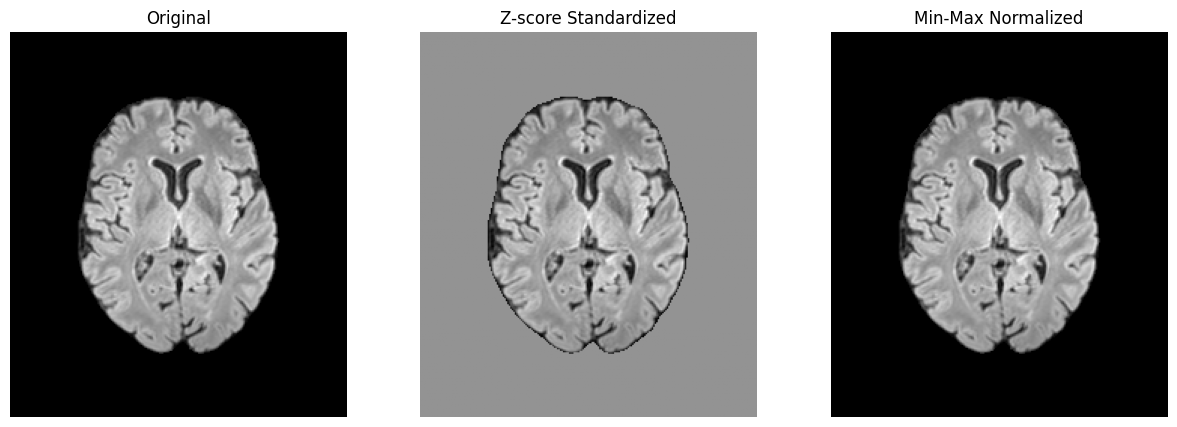

In [7]:
if 'sample_volume' in globals():
    raw = clean_image(sample_volume)
    standardized = zscore_standardize(raw)
    normalized = minmax_normalize(raw)

    print("Raw range:", raw.min(), "to", raw.max())
    print("Standardized range:", standardized.min(), "to", standardized.max())
    print("Normalized range:", normalized.min(), "to", normalized.max())

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(middle_slice(raw).T, cmap="gray", origin="lower")
    axes[0].set_title("Original")
    axes[1].imshow(middle_slice(standardized).T, cmap="gray", origin="lower")
    axes[1].set_title("Z-score Standardized")
    axes[2].imshow(middle_slice(normalized).T, cmap="gray", origin="lower")
    axes[2].set_title("Min-Max Normalized")

    for ax in axes:
        ax.axis("off")
    plt.show()

In [8]:
# Data-cleaning checks for an MRI volume
def image_quality_report(img):
    img = np.asarray(img)

    return {
        "shape": img.shape,
        "dtype": str(img.dtype),
        "nan_count": int(np.isnan(img).sum()),
        "positive_inf_count": int(np.isposinf(img).sum()),
        "negative_inf_count": int(np.isneginf(img).sum()),
        "zero_count": int((img == 0).sum()),
        "min": float(np.nanmin(img)),
        "max": float(np.nanmax(img)),
        "mean": float(np.nanmean(img)),
        "std": float(np.nanstd(img)),
    }

if 'sample_volume' in globals():
    pd.Series(image_quality_report(sample_volume))

# T3 — Preprocessing: Redundant Data Removal + Missing Data

This section treats preprocessing at the **case/modality level**.

We check:

- missing modalities,
- incomplete patient/case records,
- duplicate files,
- duplicate image content,
- inconsistent dimensions.

A missing modality should not silently be treated as a valid zero-valued scan.

In [9]:
# Build a simple case inventory from common BraTS naming conventions.
MODALITIES = ["flair", "t1ce", "t1", "t2", "seg"]

def infer_modality(path):
    name = path.name.lower()
    for modality in MODALITIES:
        if f"_{modality}" in name or name.endswith(f"{modality}.nii") or name.endswith(f"{modality}.nii.gz"):
            return modality
    return "unknown"

case_records = []
for f in nii_files:
    case_name = f.name
    modality = infer_modality(f)
    case_records.append({
        "file": str(f),
        "filename": case_name,
        "modality": modality,
        "size_bytes": f.stat().st_size
    })

inventory = pd.DataFrame(case_records)

if not inventory.empty:
    display(inventory.head())
else:
    print("No NIfTI inventory available yet.")

,file,filename,modality,size_bytes
0,C:\Users\Anushka\Downloads\HER_Biomedical_Imag...,BraTS20_Training_001_flair.nii.gz,flair,7229373
1,C:\Users\Anushka\Downloads\HER_Biomedical_Imag...,BraTS20_Training_001_t2.nii.gz,t2,7104127
2,C:\Users\Anushka\Downloads\HER_Biomedical_Imag...,BraTS20_Training_002_flair.nii.gz,flair,5126152
3,C:\Users\Anushka\Downloads\HER_Biomedical_Imag...,BraTS20_Training_002_t2.nii.gz,t2,5188757
4,C:\Users\Anushka\Downloads\HER_Biomedical_Imag...,BraTS20_Training_206_flair.nii.gz,flair,2783972


In [10]:
# Missing-modality analysis
if not inventory.empty:
    def case_id_from_filename(name):
        # Remove modality suffix for common BraTS-style names.
        stem = name.lower().replace(".nii.gz", "").replace(".nii", "")
        for modality in MODALITIES:
            stem = stem.replace("_" + modality, "")
        return stem

    inventory["case_id"] = inventory["filename"].map(case_id_from_filename)

    modality_table = inventory.pivot_table(
        index="case_id",
        columns="modality",
        values="filename",
        aggfunc="count",
        fill_value=0
    )

    display(modality_table)

    required = ["flair", "t1", "t1ce", "t2", "seg"]
    modality_table = modality_table.reindex(columns=required, fill_value=0)
    available_required = required

    missing_report = modality_table[
        [m for m in available_required if m in modality_table.columns]
    ].eq(0)

    print("Cases with at least one missing required modality:")
    display(missing_report[missing_report.any(axis=1)].head(20))

modality,flair,seg,t1,t1ce,t2
case_id,,,,,
brats20_training_001,1,0,0,0,1
brats20_training_002,1,0,0,0,1
brats20_training_206,1,1,1,1,1
brats20_training_218,1,1,1,1,1
brats20_training_306,1,1,1,1,1
brats20_training_318,1,1,1,1,1
brats20_training_449,1,1,1,1,1
brats20_training_457,1,1,1,1,1


Cases with at least one missing required modality:


modality,flair,t1,t1ce,t2,seg
case_id,,,,,
brats20_training_001,False,True,True,False,True
brats20_training_002,False,True,True,False,True


In [11]:
# File-level duplicate detection using size + SHA256.
import hashlib

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

if nii_files:
    hashes = []
    for f in nii_files:
        try:
            hashes.append(sha256_file(f))
        except Exception:
            hashes.append(None)

    duplicate_df = pd.DataFrame({
        "file": [str(f) for f in nii_files],
        "sha256": hashes
    })

    duplicate_groups = duplicate_df[
        duplicate_df["sha256"].duplicated(keep=False)
    ].sort_values("sha256")

    print("Exact duplicate files:")
    display(duplicate_groups)

Exact duplicate files:


,file,sha256


# T4 — Biomedical Image Processing

We now apply four standard biomedical-image processing operations:

1. **Enhancement** — improve contrast
2. **Restoration** — reduce noise/degradation
3. **Segmentation** — isolate the region of interest
4. **Compression** — demonstrate storage reduction and its effect

## 4.1 Enhancement — CLAHE

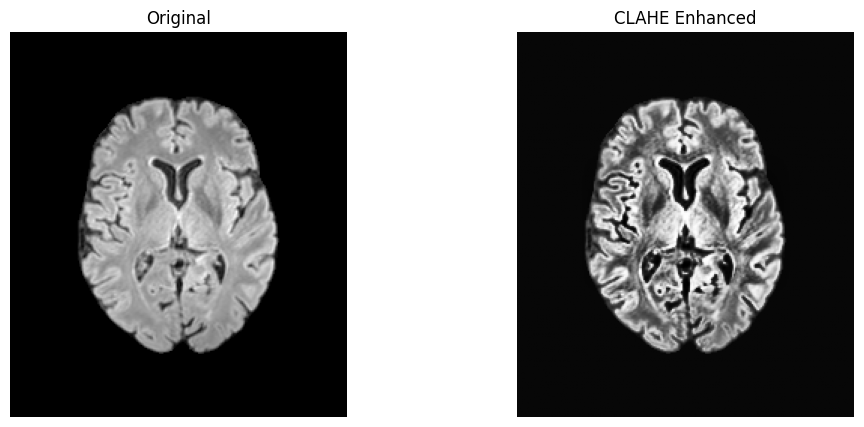

In [12]:
def enhance_clahe(slice_img):
    img = minmax_normalize(slice_img)
    if exposure is None:
        return img
    return exposure.equalize_adapthist(img, clip_limit=0.03)

if 'sample_volume' in globals():
    s = middle_slice(sample_volume)
    enhanced = enhance_clahe(s)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(s.T, cmap="gray", origin="lower")
    ax[0].set_title("Original")
    ax[1].imshow(enhanced.T, cmap="gray", origin="lower")
    ax[1].set_title("CLAHE Enhanced")
    for a in ax:
        a.axis("off")
    plt.show()

## 4.2 Restoration — denoising

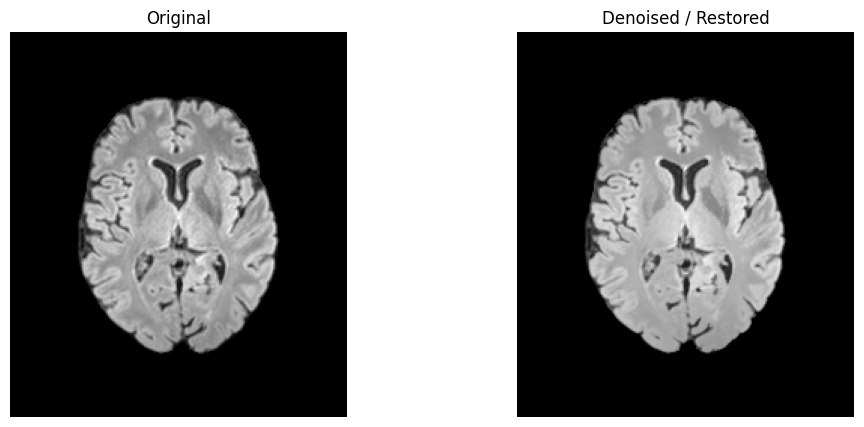

In [13]:
def restore_denoise(slice_img):
    img = minmax_normalize(slice_img)
    if restoration is None:
        return img
    return restoration.denoise_bilateral(
        img,
        sigma_color=0.05,
        sigma_spatial=3,
        channel_axis=None
    )

if 'sample_volume' in globals():
    s = middle_slice(sample_volume)
    restored = restore_denoise(s)

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(s.T, cmap="gray", origin="lower")
    ax[0].set_title("Original")
    ax[1].imshow(restored.T, cmap="gray", origin="lower")
    ax[1].set_title("Denoised / Restored")
    for a in ax:
        a.axis("off")
    plt.show()

## 4.3 Segmentation

The project already contains segmentation-mask data in the BraTS workflow. We visualize the provided mask and create an overlay.

This is preferable to pretending that a simple threshold is equivalent to the ground-truth tumor annotation.

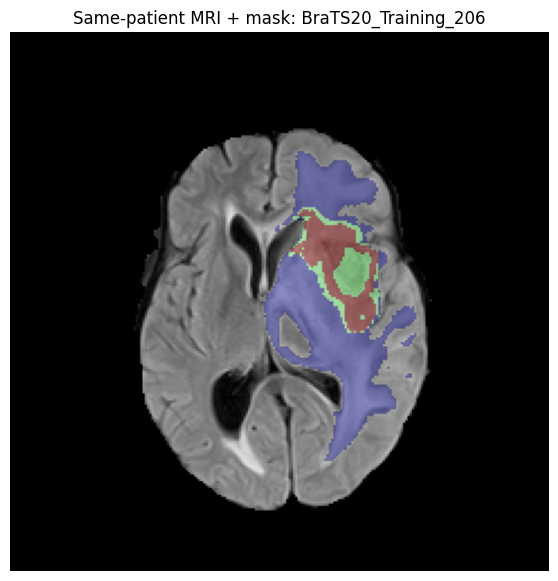

In [14]:
from her_core.io import discover_cases, load_case_modality
labeled_example = next((c for c in discover_cases(DATA_ROOT) if {"flair", "seg"} <= set(c["modalities"])), None)
if labeled_example:
    overlay_mri = load_case_modality(labeled_example, "flair")[0]
    overlay_seg = load_case_modality(labeled_example, "seg")[0]
    if overlay_mri.shape != overlay_seg.shape:
        raise ValueError("Same-patient FLAIR and SEG dimensions differ")
    z = overlay_mri.shape[2] // 2
    plt.figure(figsize=(7, 7))
    plt.imshow(overlay_mri[:, :, z].T, cmap="gray", origin="lower")
    plt.imshow(np.ma.masked_where(overlay_seg[:, :, z].T == 0, overlay_seg[:, :, z].T), cmap="jet", alpha=.45, origin="lower")
    plt.title(f"Same-patient MRI + mask: {labeled_example['case_id']}")
    plt.axis("off")
    plt.show()
else:
    print("No paired FLAIR/segmentation case available")


## 4.4 Compression

Original raw slice size: 57,344 bytes
Compressed JPEG size:    4,128 bytes
Approx. compression ratio: 13.89:1


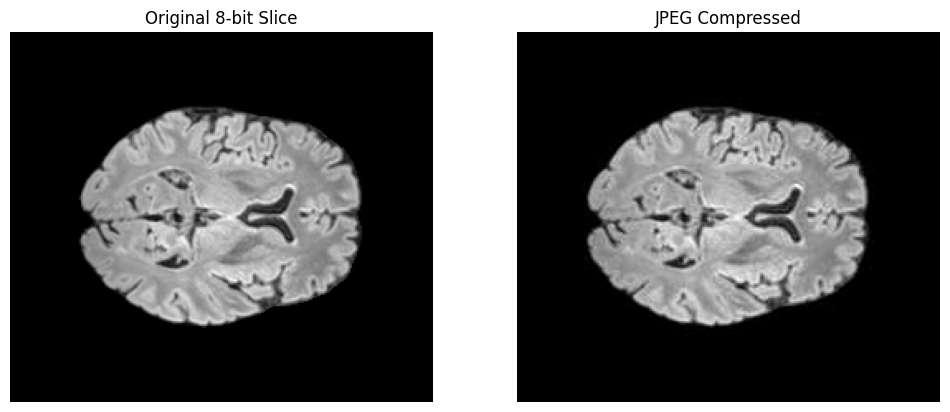

In [15]:
from PIL import Image
from io import BytesIO

def jpeg_compression_demo(slice_img, quality=50):
    img8 = (minmax_normalize(slice_img) * 255).astype(np.uint8)
    image = Image.fromarray(img8)

    buffer = BytesIO()
    image.save(buffer, format="JPEG", quality=quality)
    compressed = Image.open(BytesIO(buffer.getvalue()))

    original_bytes = img8.nbytes
    compressed_bytes = len(buffer.getvalue())
    ratio = original_bytes / compressed_bytes if compressed_bytes else np.inf

    return img8, np.array(compressed), original_bytes, compressed_bytes, ratio

if 'sample_volume' in globals():
    original, compressed, b1, b2, ratio = jpeg_compression_demo(middle_slice(sample_volume))

    print(f"Original raw slice size: {b1:,} bytes")
    print(f"Compressed JPEG size:    {b2:,} bytes")
    print(f"Approx. compression ratio: {ratio:.2f}:1")

    fig, ax = plt.subplots(1, 2, figsize=(12, 5))
    ax[0].imshow(original, cmap="gray")
    ax[0].set_title("Original 8-bit Slice")
    ax[1].imshow(compressed, cmap="gray")
    ax[1].set_title("JPEG Compressed")
    for a in ax:
        a.axis("off")
    plt.show()

# T5 — Biomedical Image Analysis Techniques

This tutorial demonstrates:

- **SIFT** — local feature detection and description
- **RANSAC** — robust geometric model estimation / outlier rejection
- **CNN** — learned image representation and classification

The SIFT/RANSAC portion uses two related MRI slices. The CNN portion is intentionally small and educational so it can be trained in a notebook without requiring a large pretrained model.

## 5.1 SIFT feature extraction

Number of SIFT keypoints: 385


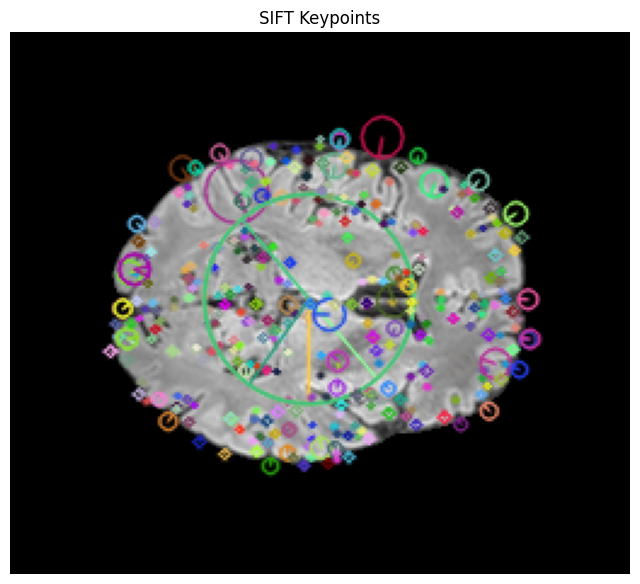

In [16]:
# T5 reusable analysis API (also used by the web UI / FastAPI endpoint)
from her_core.sift_ransac import analyze_mri_sift_ransac
from her_core.preprocess import minmax_normalize, slice_to_uint8

def sift_features(slice_img):
    """Backward-compatible helper used by earlier tutorial cells."""
    if cv2 is None:
        raise ImportError("Install OpenCV: pip install opencv-python")
    img = slice_to_uint8(slice_img)
    sift = cv2.SIFT_create()
    keypoints, descriptors = sift.detectAndCompute(img, None)
    return img, keypoints, descriptors

if 'sample_volume' in globals():
    s = middle_slice(sample_volume)
    try:
        sift_img, keypoints, descriptors = sift_features(s)
        print("Number of SIFT keypoints:", len(keypoints))
        vis = cv2.drawKeypoints(
            sift_img, keypoints, None,
            flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
        )
        plt.figure(figsize=(8, 8))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title("SIFT Keypoints")
        plt.axis("off")
        plt.show()
    except Exception as e:
        print("SIFT demo skipped:", e)


## 5.2 RANSAC-based feature matching

**UI demo:** launch the project server and open **Image Analysis**:

```bash
cd HER_Biomedical_Image_Tutorials
py -3 -m pip install -r requirements.txt
py -3 -m uvicorn backend.main:app --reload --host 127.0.0.1 --port 8000
```

Then open http://127.0.0.1:8000/image-analysis

**API:** `POST /api/image-analysis/sift-ransac`

Pipeline:

MRI slices → preprocessing → SIFT keypoints → descriptors → feature matching → RANSAC → inlier matches → visualization


SIFT found 385 / 365 keypoints; 44 good matches; RANSAC kept 35 inliers (79.5%).
Keypoints slice1/slice2: 385 365
Good SIFT matches: 44
RANSAC inliers: 35
RANSAC outliers: 9
Inlier ratio: 79.5%


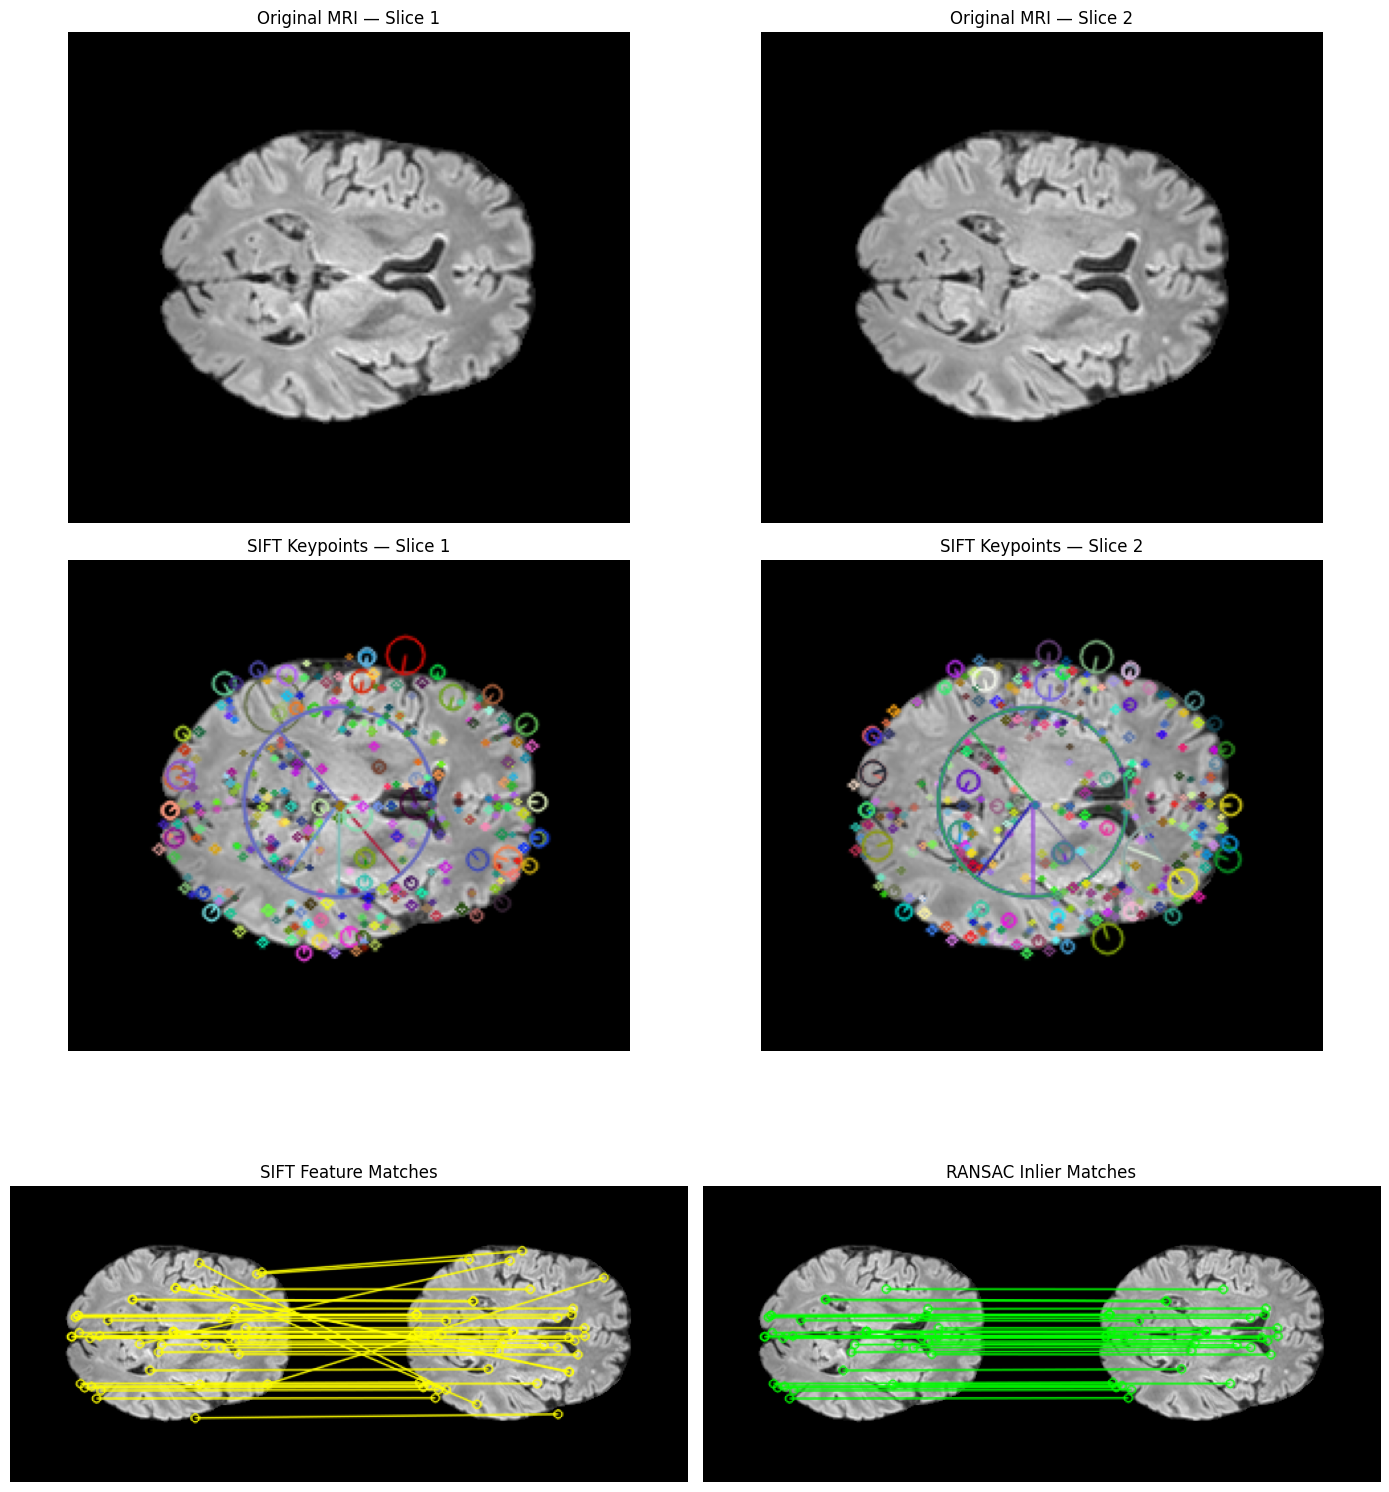

In [17]:
# Full SIFT + RANSAC demonstration on two nearby MRI slices
# (same function used by POST /api/image-analysis/sift-ransac)

def sift_ransac_match(img1, img2):
    """Legacy wrapper kept for notebook continuity."""
    return analyze_mri_sift_ransac(img1, img2, return_base64=False)

if 'sample_volume' in globals() and cv2 is not None:
    z1 = sample_volume.shape[2] // 2
    z2 = min(z1 + 2, sample_volume.shape[2] - 1)
    img1 = sample_volume[:, :, z1]
    img2 = sample_volume[:, :, z2]

    try:
        result = analyze_mri_sift_ransac(img1, img2, return_base64=False)
        print(result["message"])
        print("Keypoints slice1/slice2:", result["keypoints_image1"], result["keypoints_image2"])
        print("Good SIFT matches:", result["good_matches"])
        print("RANSAC inliers:", result["ransac_inliers"])
        print("RANSAC outliers:", result["ransac_outliers"])
        print("Inlier ratio: {:.1f}%".format(100 * result["inlier_ratio"]))

        fig, axes = plt.subplots(3, 2, figsize=(14, 16))
        axes[0, 0].imshow(result["original_image1"][:, :, ::-1])
        axes[0, 0].set_title("Original MRI — Slice 1")
        axes[0, 1].imshow(result["original_image2"][:, :, ::-1])
        axes[0, 1].set_title("Original MRI — Slice 2")
        axes[1, 0].imshow(result["sift_visualization_1"][:, :, ::-1])
        axes[1, 0].set_title("SIFT Keypoints — Slice 1")
        axes[1, 1].imshow(result["sift_visualization_2"][:, :, ::-1])
        axes[1, 1].set_title("SIFT Keypoints — Slice 2")
        axes[2, 0].imshow(result["matches_visualization"][:, :, ::-1])
        axes[2, 0].set_title("SIFT Feature Matches")
        axes[2, 1].imshow(result["ransac_visualization"][:, :, ::-1])
        axes[2, 1].set_title("RANSAC Inlier Matches")
        for ax in axes.ravel():
            ax.axis("off")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print("RANSAC demo skipped:", e)
else:
    print("Load an MRI volume first (T1 section) and install OpenCV.")


# T5 — CNN-Based Biomedical Image Analysis

This section builds a practical **2-D CNN** on top of the existing BraTS-style MRI pipeline.

- **Input:** FLAIR MRI slices (not the segmentation mask)
- **Label:** binary tumor presence from the segmentation mask (`1` if any tumor pixel exists on that slice)
- **Split:** patient-level train/validation to avoid slice leakage
- **SIFT + RANSAC cells above are unchanged**


## 1. CNN Dataset Preparation

Load labeled cases that contain both **FLAIR** and **SEG**, normalize intensities, resize to `128×128`, and create binary slice labels from the mask.


In [18]:
# TensorFlow/Keras is required for the CNN section.
try:
    import tensorflow as tf
    tf.keras.utils.set_random_seed(42)
    from tensorflow.keras import layers, models
    print("TensorFlow version:", tf.__version__)
except ImportError:
    tf = None
    print("TensorFlow is not installed.")
    print("Install it with: py -3 -m pip install tensorflow")

try:
    import seaborn as sns
except ImportError:
    sns = None
    print("Optional: py -3 -m pip install seaborn")

from her_core.cnn import (
    build_cnn_datasets,
    evaluate_tumor_cnn,
    make_tumor_cnn,
    train_tumor_cnn,
)
from her_core.io import default_data_root, discover_cases

print("Dataset root:", default_data_root())
print("Discovered cases:", [c["case_id"] for c in discover_cases()])


TensorFlow version: 2.21.0
Dataset root: C:\Users\Anushka\Downloads\HER_Biomedical_Image_Tutorials\BraTS2020
Discovered cases: ['BraTS20_Training_001', 'BraTS20_Training_002', 'BraTS20_Training_206', 'BraTS20_Training_218', 'BraTS20_Training_306', 'BraTS20_Training_318', 'BraTS20_Training_449', 'BraTS20_Training_457']


Labeled patients: ['BraTS20_Training_206', 'BraTS20_Training_218', 'BraTS20_Training_306', 'BraTS20_Training_318', 'BraTS20_Training_449', 'BraTS20_Training_457']
Train patients: ['BraTS20_Training_457', 'BraTS20_Training_449', 'BraTS20_Training_218', 'BraTS20_Training_206']
Val patients: ['BraTS20_Training_318', 'BraTS20_Training_306']
X_train: (121, 128, 128, 1) y_train counts: [53 68]
X_val: (62, 128, 128, 1) y_val counts: [30 32]


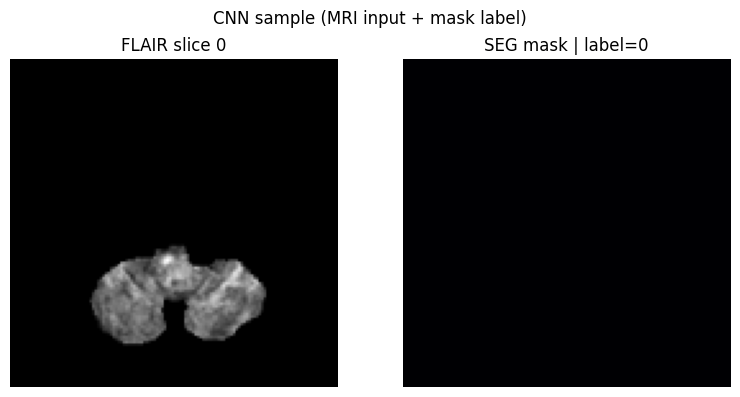

In [19]:
# Build a compact 2-D CNN dataset from FLAIR + SEG volumes.
# max_slices_per_case keeps the experiment practical on CPU/GPU.

cnn_data = None
try:
    cnn_data = build_cnn_datasets(
        data_root=DATA_ROOT if "DATA_ROOT" in globals() else None,
        target_size=(128, 128),
        max_slices_per_case=36,
        val_ratio=0.34,
        seed=42,
    )
except Exception as e:
    print("CNN dataset preparation failed:", e)
    print("Ensure BraTS2020 cases include both *_flair.nii.gz and *_seg.nii.gz")
    print("You can run: py -3 scripts/download_labeled_brats_sample.py")

if cnn_data is not None:
    print("Labeled patients:", cnn_data["labeled_cases"])
    print("Train patients:", cnn_data["train_case_ids"])
    print("Val patients:", cnn_data["val_case_ids"])
    print("X_train:", cnn_data["X_train"].shape, "y_train counts:", np.bincount(cnn_data["y_train"].astype(int)))
    print("X_val:", cnn_data["X_val"].shape, "y_val counts:", np.bincount(cnn_data["y_val"].astype(int)))

    # Quick visual check: one MRI slice and its mask-derived label
    demo = cnn_data["train_records"][0]
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(demo.image.T, cmap="gray", origin="lower")
    axes[0].set_title(f"FLAIR slice {demo.slice_idx}")
    axes[1].imshow(demo.mask.T, cmap="magma", origin="lower")
    axes[1].set_title(f"SEG mask | label={demo.label}")
    for ax in axes:
        ax.axis("off")
    plt.suptitle("CNN sample (MRI input + mask label)")
    plt.tight_layout()
    plt.show()


## 2. Patient-Level Train/Validation Split

Patients are assigned entirely to train or validation. Slices from the same patient never appear in both sets.


In [20]:
if cnn_data is not None:
    print("Patient-level split")
    print("  train_idx / train patients:", cnn_data["train_case_ids"])
    print("  val_idx / val patients:", cnn_data["val_case_ids"])
    overlap = set(cnn_data["train_case_ids"]) & set(cnn_data["val_case_ids"])
    print("  patient overlap between train and val:", overlap if overlap else "None (good)")


Patient-level split
  train_idx / train patients: ['BraTS20_Training_457', 'BraTS20_Training_449', 'BraTS20_Training_218', 'BraTS20_Training_206']
  val_idx / val patients: ['BraTS20_Training_318', 'BraTS20_Training_306']
  patient overlap between train and val: None (good)


## 3. CNN Architecture

Input shape: `128×128×1`

`Conv(32) → Pool → Conv(64) → Pool → Conv(128) → Pool → Flatten → Dense(128) → Dropout(0.5) → Dense(1, sigmoid)`


In [21]:
cnn_model = None
if tf is None:
    print("Skip architecture: install TensorFlow first.")
elif cnn_data is None:
    print("Skip architecture: CNN dataset unavailable.")
else:
    cnn_model = make_tumor_cnn(input_shape=cnn_data["X_train"].shape[1:])
    cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,233 (16.35 MB)

 Trainable params: 4,287,233 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Model Training

Train for a small number of epochs with validation monitoring and EarlyStopping.


In [22]:
history = None
if cnn_model is None:
    print("Skipping training.")
else:
    history = train_tumor_cnn(
        cnn_model,
        cnn_data["X_train"],
        cnn_data["y_train"],
        cnn_data["X_val"],
        cnn_data["y_val"],
        epochs=int(os.environ.get("HER_CNN_EPOCHS", "8")),
        batch_size=16,
    )
    print("Training finished.")


1/8 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.5000 - loss: 0.6975

2/8 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step - accuracy: 0.6094 - loss: 0.6705

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step - accuracy: 0.6701 - loss: 0.6315

4/8 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.6940 - loss: 0.6329

5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.7077 - loss: 0.6407

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.7165 - loss: 0.6424

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step - accuracy: 0.7162 - loss: 0.6484

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - accuracy: 0.7134 - loss: 0.6539 

8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 147ms/step - accuracy: 0.6942 - loss: 0.6924 - val_accuracy: 0.7419 - val_loss: 0.5947


Training finished.


## 5. Training Performance


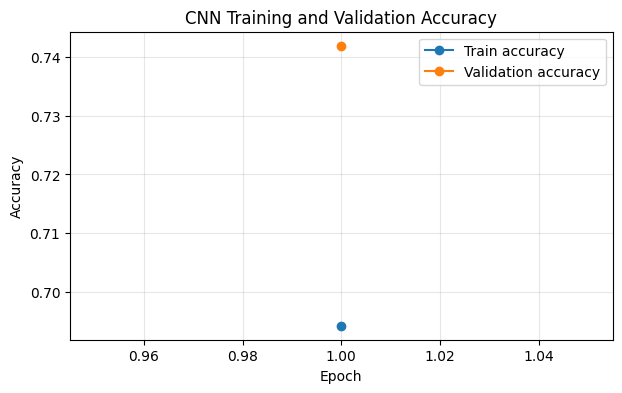

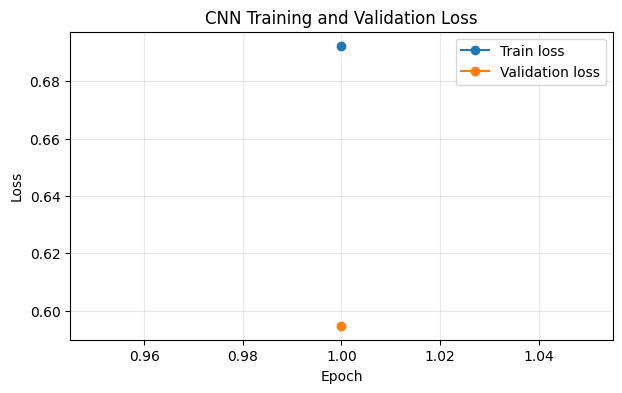

In [23]:
if history is not None:
    hist = history.history
    epochs_axis = range(1, len(hist["loss"]) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs_axis, hist["accuracy"], marker="o", label="Train accuracy")
    plt.plot(epochs_axis, hist.get("val_accuracy", []), marker="o", label="Validation accuracy")
    plt.title("CNN Training and Validation Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs_axis, hist["loss"], marker="o", label="Train loss")
    plt.plot(epochs_axis, hist.get("val_loss", []), marker="o", label="Validation loss")
    plt.title("CNN Training and Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
else:
    print("No training history available.")


## 6. CNN Evaluation


In [24]:
cnn_eval = None
if cnn_model is None:
    print("Skipping evaluation.")
else:
    cnn_eval = evaluate_tumor_cnn(cnn_model, cnn_data["X_val"], cnn_data["y_val"])
    print("Validation accuracy: {:.3f}".format(cnn_eval["accuracy"]))
    print("Precision: {:.3f}".format(cnn_eval["precision"]))
    print("Recall: {:.3f}".format(cnn_eval["recall"]))
    print("F1-score: {:.3f}".format(cnn_eval["f1"]))
    print("\nClassification report:\n")
    print(cnn_eval["classification_report"])


Validation accuracy: 0.742
Precision: 0.786
Recall: 0.688
F1-score: 0.733

Classification report:

               precision    recall  f1-score   support

     No Tumor       0.71      0.80      0.75        30
Tumor Present       0.79      0.69      0.73        32

     accuracy                           0.74        62
    macro avg       0.75      0.74      0.74        62
 weighted avg       0.75      0.74      0.74        62



## 7. Confusion Matrix


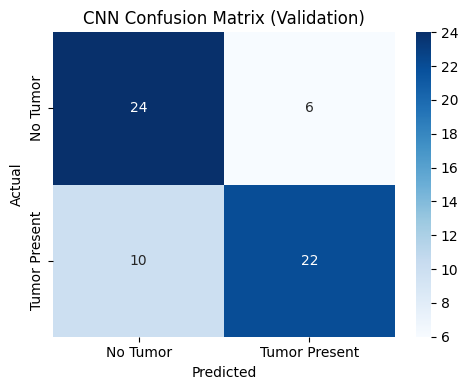

In [25]:
if cnn_eval is not None:
    cm = cnn_eval["confusion_matrix"]
    plt.figure(figsize=(5, 4))
    if sns is not None:
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["No Tumor", "Tumor Present"],
            yticklabels=["No Tumor", "Tumor Present"],
        )
    else:
        plt.imshow(cm, cmap="Blues")
        for (i, j), v in np.ndenumerate(cm):
            plt.text(j, i, str(v), ha="center", va="center")
        plt.xticks([0, 1], ["No Tumor", "Tumor Present"])
        plt.yticks([0, 1], ["No Tumor", "Tumor Present"])
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title("CNN Confusion Matrix (Validation)")
    plt.tight_layout()
    plt.show()


## 8. MRI Prediction Demonstration

Predict on real validation FLAIR slices and compare against the ground-truth segmentation mask.


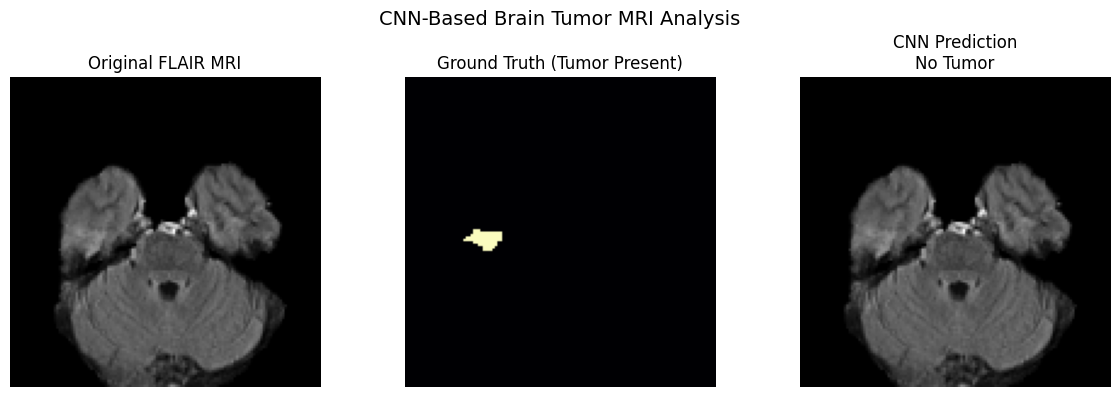

CNN Prediction: No Tumor
Tumor Probability: 0.45
Ground truth: Tumor Present
Case / slice: BraTS20_Training_318 35


In [26]:
if cnn_model is None or cnn_data is None or not cnn_data["val_records"]:
    print("Skipping MRI prediction demo.")
else:
    val_records = cnn_data["val_records"]
    probs = cnn_eval["y_prob"]
    preds = cnn_eval["y_pred"]

    # Prefer a true-positive tumor slice for a clearer demo; otherwise first val slice.
    demo_idx = 0
    for i, rec in enumerate(val_records):
        if rec.label == 1:
            demo_idx = i
            break

    rec = val_records[demo_idx]
    prob = float(probs[demo_idx])
    pred = int(preds[demo_idx])
    pred_label = "Tumor Present" if pred == 1 else "No Tumor"
    true_label = "Tumor Present" if rec.label == 1 else "No Tumor"

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(rec.image.T, cmap="gray", origin="lower")
    axes[0].set_title("Original FLAIR MRI")
    axes[1].imshow(rec.mask.T, cmap="magma", origin="lower")
    axes[1].set_title(f"Ground Truth ({true_label})")
    axes[2].imshow(rec.image.T, cmap="gray", origin="lower")
    axes[2].set_title(f"CNN Prediction\n{pred_label}")
    for ax in axes:
        ax.axis("off")
    plt.suptitle("CNN-Based Brain Tumor MRI Analysis", fontsize=14)
    plt.tight_layout()
    plt.show()

    print("CNN Prediction:", pred_label)
    print("Tumor Probability: {:.2f}".format(prob))
    print("Ground truth:", true_label)
    print("Case / slice:", rec.case_id, rec.slice_idx)


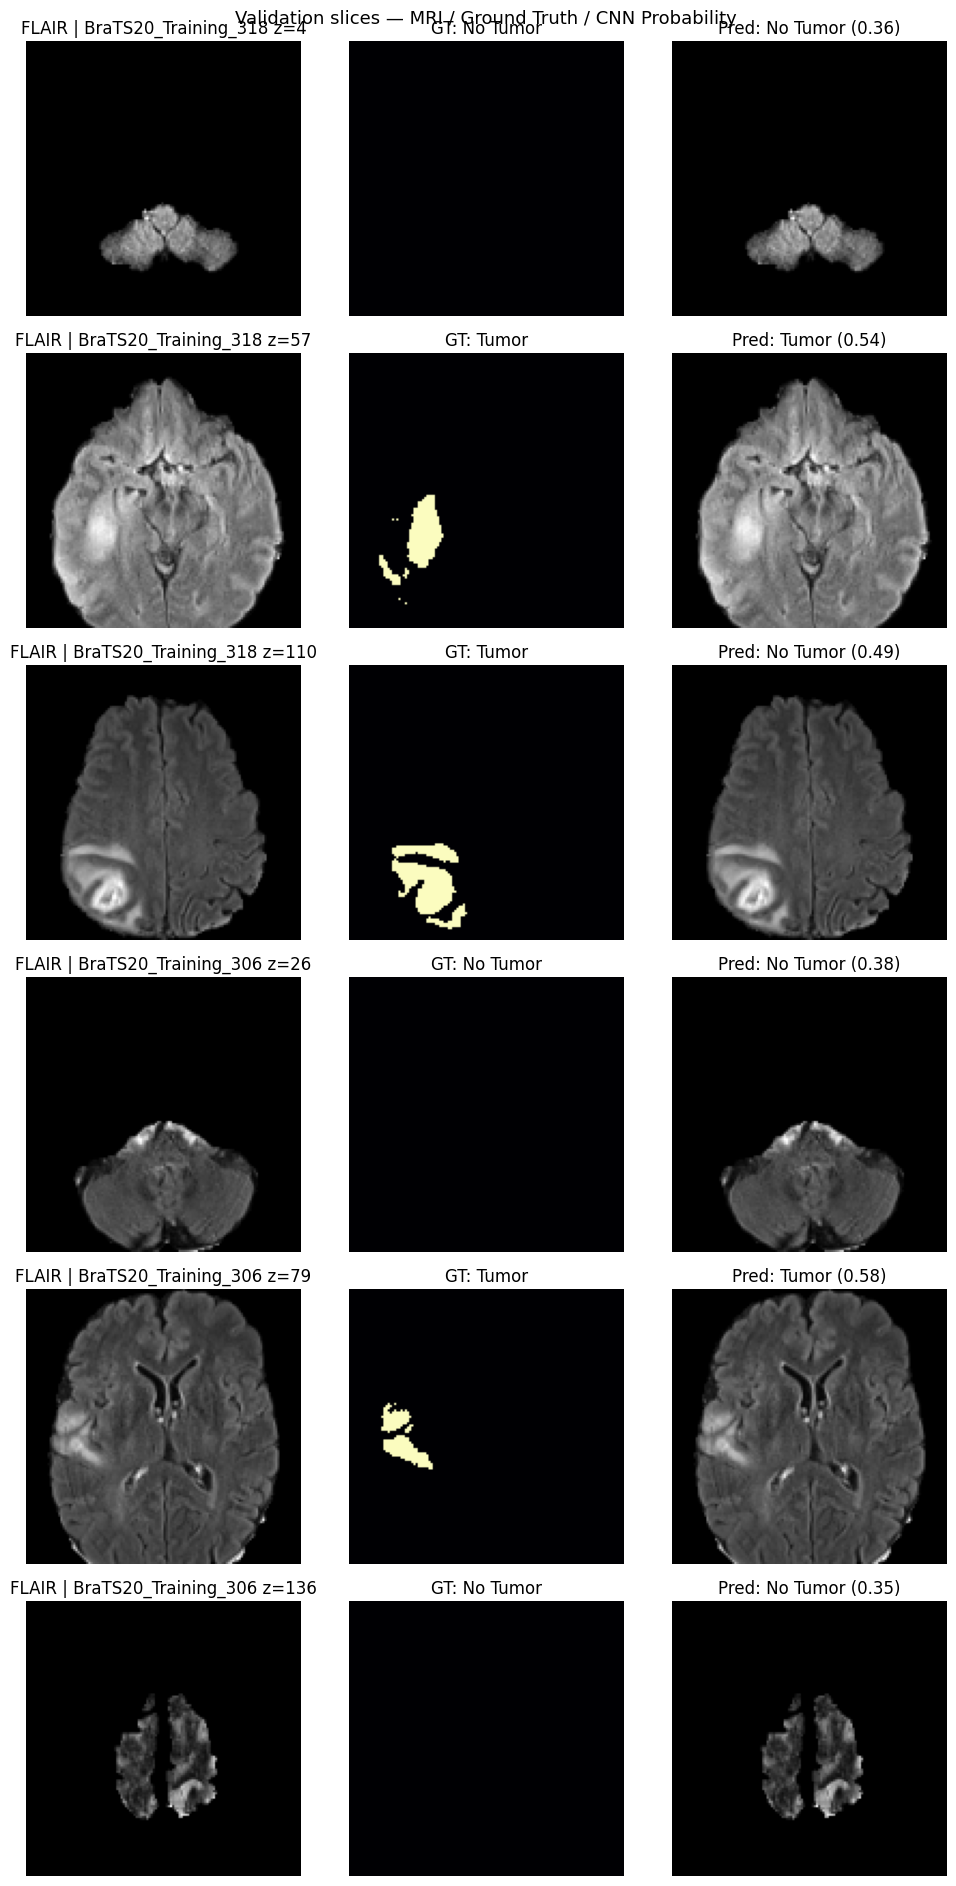


Concise metrics


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,861,701 (49.06 MB)

 Trainable params: 4,287,233 (16.35 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 8,574,468 (32.71 MB)

None
Val Acc=0.742 | Precision=0.786 | Recall=0.688 | F1=0.733


In [27]:
# Optional: several validation slices with predicted tumor probability
if cnn_model is not None and cnn_data is not None and len(cnn_data["val_records"]) > 0:
    n_show = min(6, len(cnn_data["val_records"]))
    # Spread across validation set
    idxs = np.linspace(0, len(cnn_data["val_records"]) - 1, n_show).astype(int)
    fig, axes = plt.subplots(n_show, 3, figsize=(10, 3.2 * n_show))
    if n_show == 1:
        axes = np.array([axes])

    for row, i in enumerate(idxs):
        rec = cnn_data["val_records"][i]
        prob = float(cnn_eval["y_prob"][i])
        pred = "Tumor" if cnn_eval["y_pred"][i] == 1 else "No Tumor"
        gt = "Tumor" if rec.label == 1 else "No Tumor"
        axes[row, 0].imshow(rec.image.T, cmap="gray", origin="lower")
        axes[row, 0].set_title(f"FLAIR | {rec.case_id} z={rec.slice_idx}")
        axes[row, 1].imshow(rec.mask.T, cmap="magma", origin="lower")
        axes[row, 1].set_title(f"GT: {gt}")
        axes[row, 2].imshow(rec.image.T, cmap="gray", origin="lower")
        axes[row, 2].set_title(f"Pred: {pred} ({prob:.2f})")
        for ax in axes[row]:
            ax.axis("off")

    plt.suptitle("Validation slices — MRI / Ground Truth / CNN Probability", fontsize=13)
    plt.tight_layout()
    plt.show()

    print("\nConcise metrics")
    print(cnn_model.summary())
    print(
        "Val Acc={:.3f} | Precision={:.3f} | Recall={:.3f} | F1={:.3f}".format(
            cnn_eval["accuracy"],
            cnn_eval["precision"],
            cnn_eval["recall"],
            cnn_eval["f1"],
        )
    )


# T6 — Biomedical Image Visualization

Visualization is essential for checking preprocessing results and communicating biomedical-image findings.

We include:

- multimodal comparison,
- intensity histograms,
- segmentation overlays,
- enhancement comparison,
- 3-D volume visualization when practical.

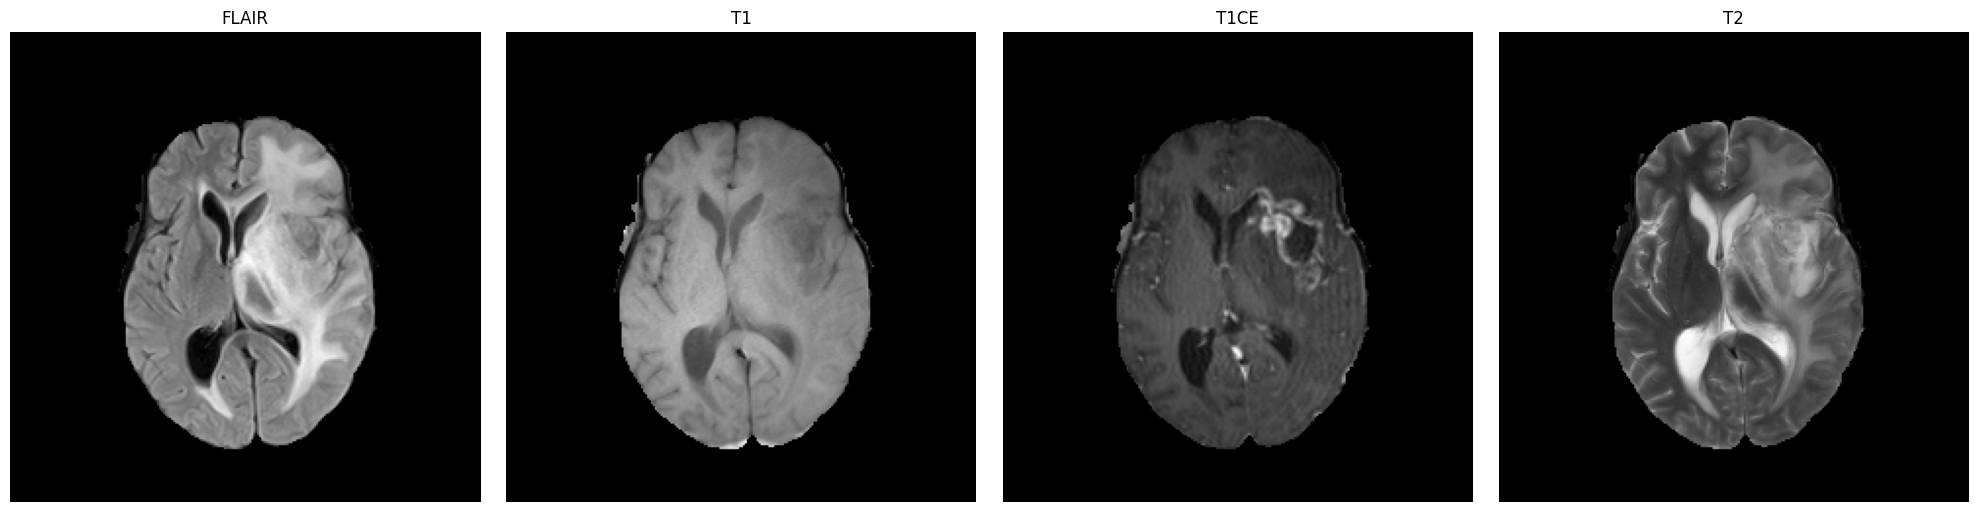

In [28]:
def plot_modalities(modality_paths):
    loaded = {}

    for name, path in modality_paths.items():
        if path is not None and Path(path).exists() and nib is not None:
            loaded[name] = load_nifti(path)[0]

    if not loaded:
        print("No modality files available.")
        return

    fig, axes = plt.subplots(1, len(loaded), figsize=(5 * len(loaded), 5))
    if len(loaded) == 1:
        axes = [axes]

    for ax, (name, vol) in zip(axes, loaded.items()):
        ax.imshow(middle_slice(vol).T, cmap="gray", origin="lower")
        ax.set_title(name.upper())
        ax.axis("off")

    plt.tight_layout()
    plt.show()

# Compare modalities from the same patient only.
from her_core.io import discover_cases
cases_for_display = discover_cases(DATA_ROOT)
if cases_for_display:
    same_case = max(cases_for_display, key=lambda c: len(c["modalities"]))
    plot_modalities({m: p for m, p in same_case["modalities"].items() if m != "seg"})


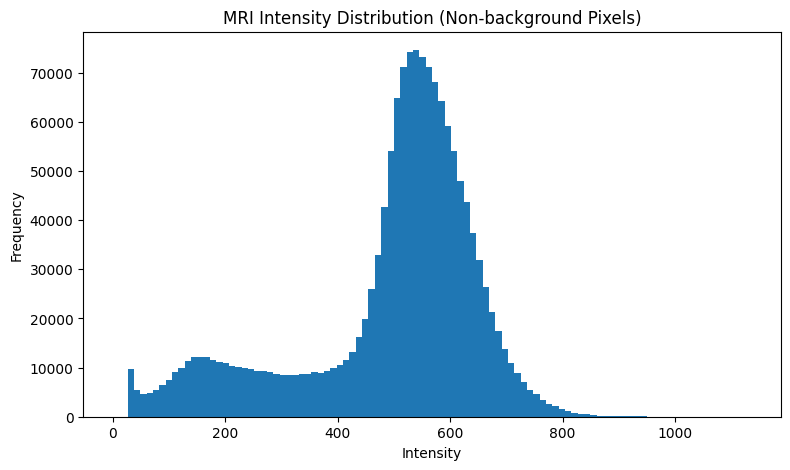

In [29]:
# Intensity histogram
if 'sample_volume' in globals():
    values = sample_volume[sample_volume != 0].ravel()

    plt.figure(figsize=(9, 5))
    plt.hist(values, bins=100)
    plt.title("MRI Intensity Distribution (Non-background Pixels)")
    plt.xlabel("Intensity")
    plt.ylabel("Frequency")
    plt.show()

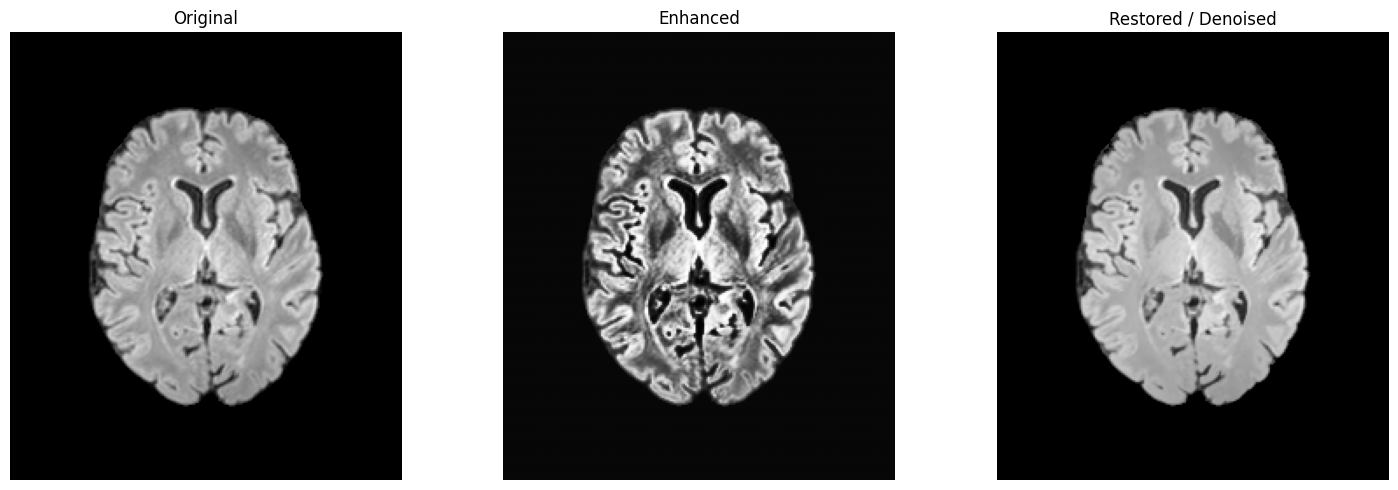

In [30]:
# Before/after visualization
if 'sample_volume' in globals():
    s = middle_slice(sample_volume)
    enhanced = enhance_clahe(s)
    restored = restore_denoise(s)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(s.T, cmap="gray", origin="lower")
    axes[0].set_title("Original")
    axes[1].imshow(enhanced.T, cmap="gray", origin="lower")
    axes[1].set_title("Enhanced")
    axes[2].imshow(restored.T, cmap="gray", origin="lower")
    axes[2].set_title("Restored / Denoised")

    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 6.1 Optional 3-D visualization

The following cell provides a lightweight 3-D visualization of voxels above a chosen intensity percentile.

For large MRI volumes, 3-D plots can be memory-intensive, so this is optional.

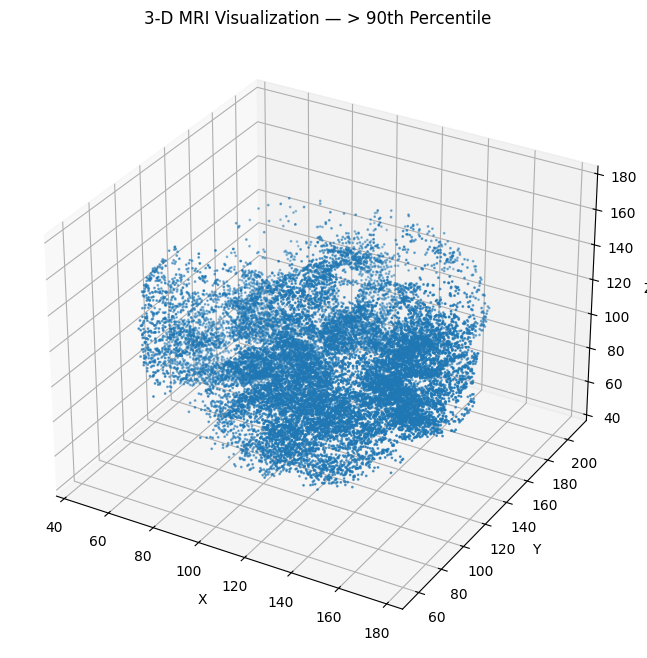

In [31]:
try:
    from mpl_toolkits.mplot3d import Axes3D
except ImportError:
    Axes3D = None

def plot_3d_threshold(volume, percentile=85, stride=4):
    data = clean_image(volume)
    threshold = np.percentile(data[data > 0], percentile) if np.any(data > 0) else 0

    coords = np.argwhere(data > threshold)
    if len(coords) == 0:
        print("No voxels above threshold.")
        return

    coords = coords[::stride]

    fig = plt.figure(figsize=(9, 8))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(coords[:, 0], coords[:, 1], coords[:, 2], s=1)
    ax.set_title(f"3-D MRI Visualization — > {percentile}th Percentile")
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    plt.show()

if 'sample_volume' in globals():
    plot_3d_threshold(sample_volume, percentile=90, stride=8)

# T1–T6 Baseline Summary

| Tutorial | Main practical implementation |
|---|---|
| **T1** | Understand multimodal MRI/NIfTI structure |
| **T2** | Cleaning, z-score standardization, normalization |
| **T3** | Missing modality detection and duplicate removal |
| **T4** | CLAHE enhancement, denoising/restoration, segmentation overlay, compression |
| **T5** | SIFT features, RANSAC matching, CNN classification |
| **T6** | MRI visualization, histograms, overlays, 3-D visualization |

## Important note

The CNN, SIFT/RANSAC, and image-processing cells are **educational implementations**. They demonstrate the requested biomedical-image techniques using the project data; they are not intended for clinical diagnosis or deployment without proper validation.

## Appendix — Existing Project Code

The original notebook contained project-specific cells for data loading and MRI normalization. The new tutorial flow above replaces duplicated exploratory cells with reusable functions, while preserving the same overall NIfTI/BraTS workflow.

If the original notebook uses a different `DATA_ROOT`, update that one variable near the beginning of this notebook.

# T7–T15: Healthcare analytics extension

All examples run offline and are **deterministic synthetic demonstrations, never actual patient records**. No suitable non-MRI data or separate syllabus file was present. Topic names follow the supplied mission syllabus. Default data are generated locally with seed 42. Replace the demo with your own compatible, de-identified CSV using the paths below; missing external files are explicitly detected. The dashboard supports the same schemas and computations at http://127.0.0.1:8000.


In [32]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
from her_core.analytics import run_analysis, example_data

def tutorial_dataset(tutorial, csv_path=None):
    if csv_path is None:
        print("SOURCE: synthetic demonstration, seed 42, not real patient data")
        return None
    path = Path(csv_path)
    if not path.is_file():
        raise FileNotFoundError(f"Dataset absent: {path}; omit csv_path for labeled synthetic demo")
    return pd.read_csv(path)

def show_analysis(result):
    print(result["dataset"])
    display(pd.DataFrame([result["metrics"]]))
    for name, rows in result["tables"].items():
        print(name)
        display(pd.DataFrame(rows).head(12))
    for plot in result["plots"]:
        print(plot["title"])
        import base64
        display(Image(data=base64.b64decode(plot["png"])))
    for sentence in result["interpretation"] + result["warnings"]:
        print(sentence)


# T7 — Patient prediction for improved staffing

**Objective:** Patient prediction for improved staffing.

**Dataset / source:** Daily synthetic hospital operations; locally generated `example_data(7)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `date, admissions, department, occupied_beds, capacity, cost`. Only date and admissions are required; department, paired occupied_beds/capacity and cost are optional, and their KPIs are omitted when absent. **Target/output:** admissions.

**Preprocessing and method:** Validate complete consecutive daily records; aggregate by date. Fit scaled Ridge using trend and weekly calendar features, first 80% train and last 20% test. Report MAE/RMSE and training-mean baseline. Compare actual/predicted values and ceil(demand / 8 admissions per staff).

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T7, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data
Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,MAE,RMSE,baseline_MAE,train_days,test_days,workload_per_staff
0,0,3.159933,3.930053,13.867284,144,36,8


missing_values


,column,missing
0,date,0
1,admissions,0
2,department,0
3,occupied_beds,0
4,capacity,0
5,cost,0


daily


,date,admissions,occupied_beds,capacity,cost,occupancy
0,2025-01-01,71.0,71,100,26822.88,0.71
1,2025-01-02,75.0,64,100,28614.29,0.64
2,2025-01-03,85.0,51,100,22872.61,0.51
3,2025-01-04,79.0,85,100,21359.82,0.85
4,2025-01-05,58.0,65,100,25090.52,0.65
5,2025-01-06,54.0,80,100,32500.10,0.80
6,2025-01-07,62.0,68,100,32022.63,0.68
7,2025-01-08,70.0,67,100,15869.50,0.67
8,2025-01-09,81.0,90,100,18629.97,0.90
9,2025-01-10,80.0,54,100,19734.90,0.54


forecast


,date,actual,predicted,illustrative_staff
0,2025-05-25,83.0,85.938547,11
1,2025-05-26,78.0,80.169748,11
2,2025-05-27,80.0,82.670016,11
3,2025-05-28,91.0,91.665196,12
4,2025-05-29,106.0,100.490335,13
5,2025-05-30,105.0,102.608522,13
6,2025-05-31,97.0,96.533319,13
7,2025-06-01,83.0,86.948078,11
8,2025-06-02,74.0,81.179279,11
9,2025-06-03,82.0,83.679547,11


Chronological holdout: admissions


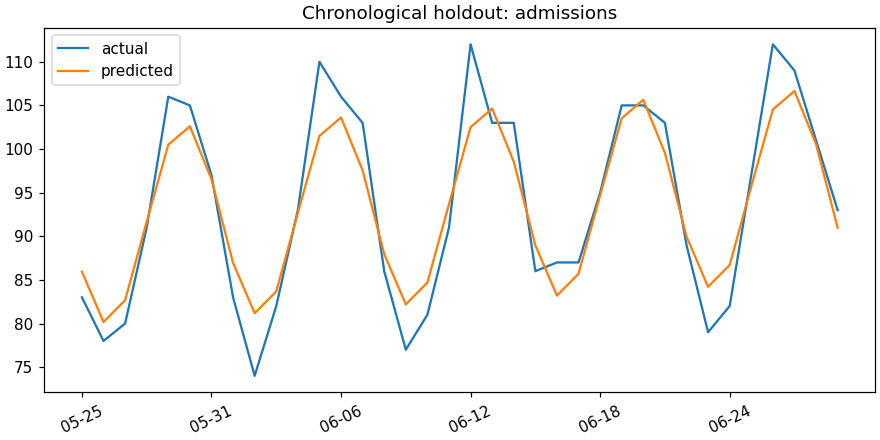

One-day demand modeled using calendar features known in advance; last 36 days held out. Illustrative staff = ceil(predicted admissions / 8); this is a workload assumption, not a staffing prescription.


In [33]:
data_t7 = tutorial_dataset(7)
result_t7 = run_analysis(7, data_t7)
show_analysis(result_t7)


# T8 — Using healthcare data for informed strategic planning — Part 1

**Objective:** Using healthcare data for informed strategic planning — Part 1.

**Dataset / source:** Daily synthetic hospital operations; locally generated `example_data(8)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `date, admissions, department, occupied_beds, capacity, cost`. Only date and admissions are required; department, paired occupied_beds/capacity and cost are optional, and their KPIs are omitted when absent. **Target/output:** Descriptive operational KPIs.

**Preprocessing and method:** Reject impossible capacity/occupancy and malformed dates. Aggregate by date and department. Compute occupancy as total occupied beds / total capacity and cost per admission; interpret resource demand using measured KPIs.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T8, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,total_admissions,occupancy_rate,total_cost
0,0,14998.0,0.717611,4573164.7


missing_values


,column,missing
0,date,0
1,admissions,0
2,department,0
3,occupied_beds,0
4,capacity,0
5,cost,0


daily


... (2 outputs left out)

,department,admissions,observations,occupancy,capacity,cost,occupancy_rate,cost_per_admission
0,Emergency,5001.0,60,4346,6000,1531155.20,0.724333,306.169806
1,Medicine,4984.0,60,4424,6000,1483887.59,0.737333,297.730255
2,Surgery,5013.0,60,4147,6000,1558121.91,0.691167,310.816260


descriptive


,index,date,admissions,occupied_beds,capacity,cost
0,count,180,180.000000,180.000000,180.0,180.000000
1,mean,2025-03-31T12:00:00.000,83.322222,71.761111,100.0,25406.470556
2,min,2025-01-01T00:00:00.000,54.000000,50.000000,100.0,15108.600000
3,25%,2025-02-14T18:00:00.000,74.000000,58.000000,100.0,20047.690000
4,50%,2025-03-31T12:00:00.000,83.000000,71.000000,100.0,26179.435000
5,75%,2025-05-15T06:00:00.000,92.250000,85.000000,100.0,30610.992500
6,max,2025-06-29T00:00:00.000,112.000000,95.000000,100.0,34982.090000
7,std,None,11.937292,14.072980,0.0,5921.685016


Daily admissions


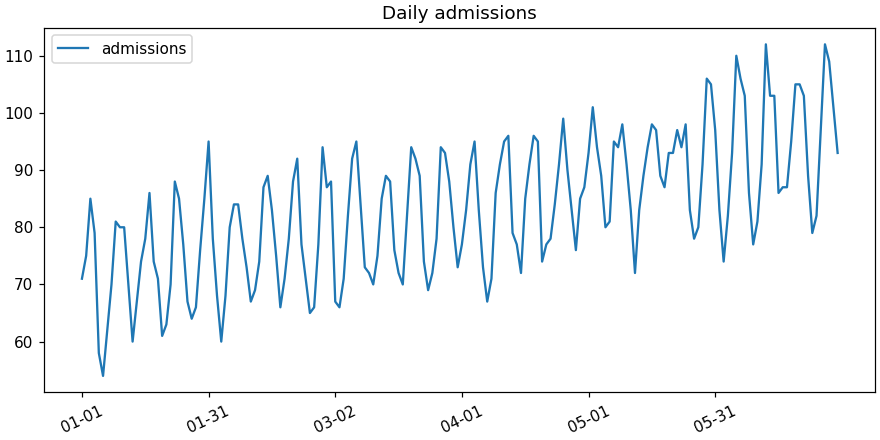

Compare measured occupancy, admissions and cost by department; these descriptive KPIs identify areas for further operational review.


In [34]:
data_t8 = tutorial_dataset(8)
result_t8 = run_analysis(8, data_t8)
show_analysis(result_t8)


# T9 — Using healthcare data for informed strategic planning — Part 2

**Objective:** Using healthcare data for informed strategic planning — Part 2.

**Dataset / source:** Daily synthetic hospital operations; locally generated `example_data(9)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `date, admissions, department, occupied_beds, capacity, cost`. Only date and admissions are required; department, paired occupied_beds/capacity and cost are optional, and their KPIs are omitted when absent. **Target/output:** Department comparison and calendar trend.

**Preprocessing and method:** Extend T8 with daily variance, linear trend slope, a Kruskal comparison and occupancy-ranked priorities. Kruskal requires independent observations; time dependence makes its p-value exploratory.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T9, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data
Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,total_admissions,occupancy_rate,total_cost,kruskal_H,kruskal_p,daily_admissions_variance,admissions_trend_per_day
0,0,14998.0,0.717611,4573164.7,0.031024,0.984608,142.498945,0.146239


missing_values


,column,missing
0,date,0
1,admissions,0
2,department,0
3,occupied_beds,0
4,capacity,0
5,cost,0


daily


,date,admissions,occupied_beds,capacity,cost,occupancy
0,2025-01-01,71.0,71,100,26822.88,0.71
1,2025-01-02,75.0,64,100,28614.29,0.64
2,2025-01-03,85.0,51,100,22872.61,0.51
3,2025-01-04,79.0,85,100,21359.82,0.85
4,2025-01-05,58.0,65,100,25090.52,0.65
5,2025-01-06,54.0,80,100,32500.10,0.80
6,2025-01-07,62.0,68,100,32022.63,0.68
7,2025-01-08,70.0,67,100,15869.50,0.67
8,2025-01-09,81.0,90,100,18629.97,0.90
9,2025-01-10,80.0,54,100,19734.90,0.54


... (3 outputs left out)

,index,date,admissions,occupied_beds,capacity,cost
0,count,180,180.000000,180.000000,180.0,180.000000
1,mean,2025-03-31T12:00:00.000,83.322222,71.761111,100.0,25406.470556
2,min,2025-01-01T00:00:00.000,54.000000,50.000000,100.0,15108.600000
3,25%,2025-02-14T18:00:00.000,74.000000,58.000000,100.0,20047.690000
4,50%,2025-03-31T12:00:00.000,83.000000,71.000000,100.0,26179.435000
5,75%,2025-05-15T06:00:00.000,92.250000,85.000000,100.0,30610.992500
6,max,2025-06-29T00:00:00.000,112.000000,95.000000,100.0,34982.090000
7,std,None,11.937292,14.072980,0.0,5921.685016


planning_priority


,department,admissions,observations,occupancy,capacity,cost,occupancy_rate,cost_per_admission
0,Medicine,4984.0,60,4424,6000,1483887.59,0.737333,297.730255
1,Emergency,5001.0,60,4346,6000,1531155.20,0.724333,306.169806
2,Surgery,5013.0,60,4147,6000,1558121.91,0.691167,310.816260


Daily admissions


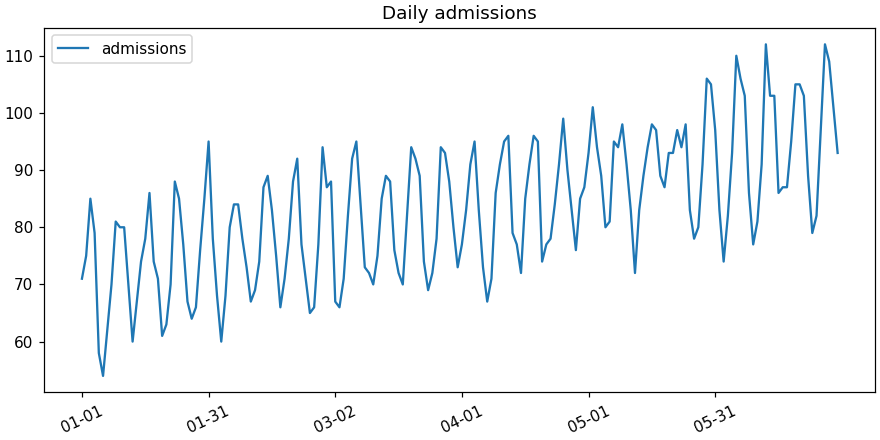

Highest observed occupancy_rate: Medicine (0.7373); review available capacity and cost evidence before allocating resources. Rank is by computed occupancy_rate only.
Kruskal comparison assumes independent observations; repeated facility/day records and temporal correlation can invalidate inferential p-values.


In [35]:
data_t9 = tutorial_dataset(9)
result_t9 = run_analysis(9, data_t9)
show_analysis(result_t9)


# T10 — Classification and clustering of clinical text data

**Objective:** Classification and clustering of clinical text data.

**Dataset / source:** Synthetic educational clinical-style text corpus; locally generated `example_data(10)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `text, label`.  **Target/output:** label.

**Preprocessing and method:** Normalize text, deduplicate identical documents and reject conflicting labels. Stratify a held-out split. Fit TF-IDF and logistic regression only on training texts. Report weighted precision/recall/F1, accuracy and confusion matrix. Fit K-means on training vectors and report cosine silhouette, sizes and terms.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T10, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,accuracy,precision,recall,F1,train_rows,test_rows,silhouette_cosine
0,0,1.0,1.0,1.0,1.0,27,9,0.297918


missing_values


,column,missing
0,text,0
1,label,0


confusion_matrix


... (6 outputs left out)

,cluster,size,terms
0,0,14,"chest, cough, ecg, inhaler, xray, wheeze"
1,1,4,"edema, echocardiogram, hypertension, failure, ..."
2,2,9,"glucose, diabetes, insulin, fatigue, monitorin..."


cluster_assignments


,text,cluster
0,diabetes fatigue glucose monitoring insulin fo...,2
1,hypertension heart failure edema echocardiogra...,1
2,hypertension heart failure edema echocardiogra...,1
3,cough wheeze asthma inhaler chest xray outpati...,0
4,chest pain angina ECG aspirin cardiology asses...,0
5,hyperglycemia thirst diabetes blood glucose re...,2
6,wheezing cough shortness breath spirometry rev...,0
7,diabetes fatigue glucose monitoring insulin re...,2
8,wheezing cough shortness breath spirometry ass...,0
9,hyperglycemia thirst diabetes blood glucose as...,2


Training document clusters


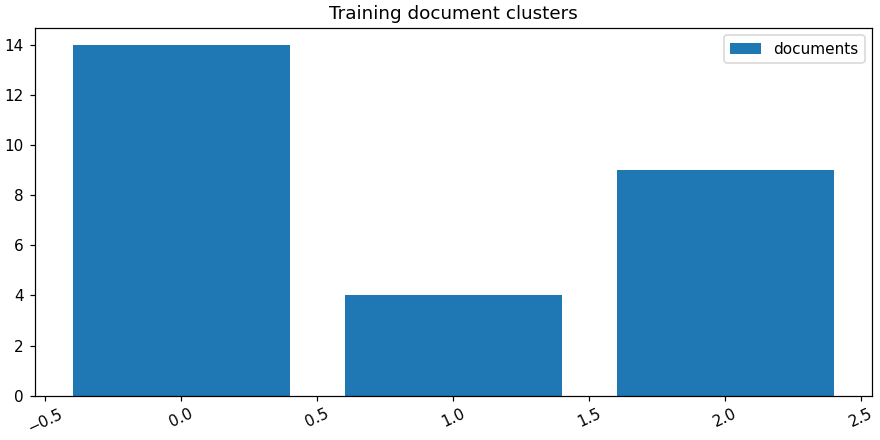

TF-IDF and classifier fitted on training texts only. Template-based synthetic examples are easy and do not estimate real clinical generalization.


In [36]:
data_t10 = tutorial_dataset(10)
result_t10 = run_analysis(10, data_t10, text="Diabetes on metformin 500 mg. MS after neurological assessment.", query="diabetes glucose")
show_analysis(result_t10)


# T11 — Information extraction and entity recognition of clinical text data

**Objective:** Information extraction and entity recognition of clinical text data.

**Dataset / source:** Synthetic educational clinical-style text corpus; locally generated `example_data(11)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `text`. For T11/T12 only text is required; label is ignored. **Target/output:** Entity mentions, not diagnoses.

**Preprocessing and method:** Use a documented lexicon for conditions, medications, investigations plus measurement regular expressions. Return source, offsets and extraction method. A short negation-cue window is illustrative. Without annotated labels no honest precision/recall estimate is available.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T11, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data
Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,mentions
0,0,3


missing_values


,column,missing
0,text,0
1,label,0


entities


,entity,category,start,end,source_text,method,possible_negation
0,Diabetes,condition/symptom,0,8,Diabetes on metformin 500 mg. MS after neurolo...,case-insensitive lexicon,False
1,metformin,medication,12,21,Diabetes on metformin 500 mg. MS after neurolo...,case-insensitive lexicon,False
2,500 mg,measurement,22,28,Diabetes on metformin 500 mg. MS after neurolo...,measurement regex,NaN


Detected text mentions by category


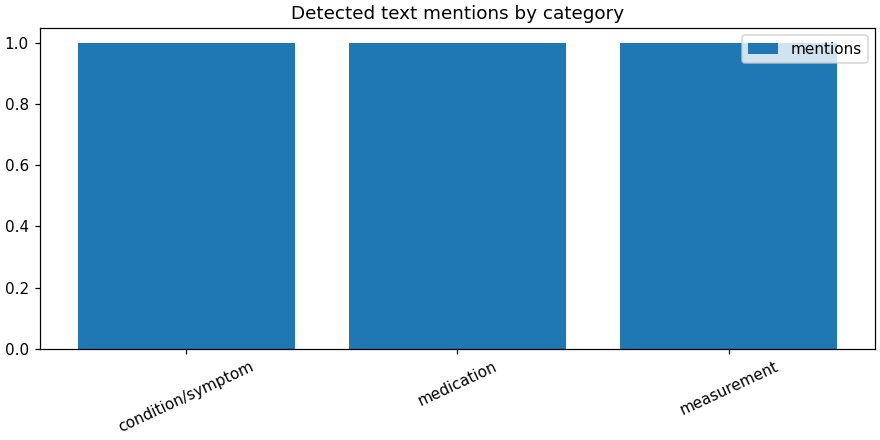

Detected mentions are not verified clinical facts. Negation flag uses a 35-character cue window and can be wrong. No annotated ground truth: precision/recall cannot be estimated.


In [37]:
data_t11 = tutorial_dataset(11)
result_t11 = run_analysis(11, data_t11, text="Diabetes on metformin 500 mg. MS after neurological assessment.", query="diabetes glucose")
show_analysis(result_t11)


# T12 — Ranking and word disambiguation of clinical text data

**Objective:** Ranking and word disambiguation of clinical text data.

**Dataset / source:** Synthetic educational clinical-style text corpus; locally generated `example_data(12)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `text`. For T11/T12 only text is required; label is ignored. **Target/output:** Lexical relevance and supported abbreviation senses.

**Preprocessing and method:** Fit TF-IDF on documents, transform the query, rank cosine similarity. Explicit MS senses: multiple sclerosis / mitral stenosis; RA: rheumatoid arthritis / right atrium. Context cue counts resolve only unique positive evidence; otherwise return ambiguous or unsupported. No annotated relevance/sense benchmark is available.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T12, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,top_relevance
0,0,0.441901


missing_values


,column,missing
0,text,0
1,label,0


ranking


,rank,document,score
0,1,diabetes glucose insulin HbA1c metformin outpa...,0.441901
1,2,diabetes glucose insulin HbA1c metformin revie...,0.441901
2,3,diabetes glucose insulin HbA1c metformin asses...,0.441901
3,4,diabetes fatigue glucose monitoring insulin re...,0.441901
4,5,diabetes fatigue glucose monitoring insulin as...,0.441901
5,6,diabetes fatigue glucose monitoring insulin ou...,0.441901
6,7,hyperglycemia thirst diabetes blood glucose ou...,0.426357
7,8,hyperglycemia thirst diabetes blood glucose re...,0.426357
8,9,hyperglycemia thirst diabetes blood glucose as...,0.426357
9,10,diabetes fatigue glucose monitoring insulin fo...,0.416761


disambiguation


,term,context,interpretation,method,cue_scores
0,MS,Diabetes on metformin 500 mg. MS after neurolo...,multiple sclerosis,explicit context cue counts,"{'multiple sclerosis': 1, 'mitral stenosis': 0}"


Document relevance (cosine similarity)


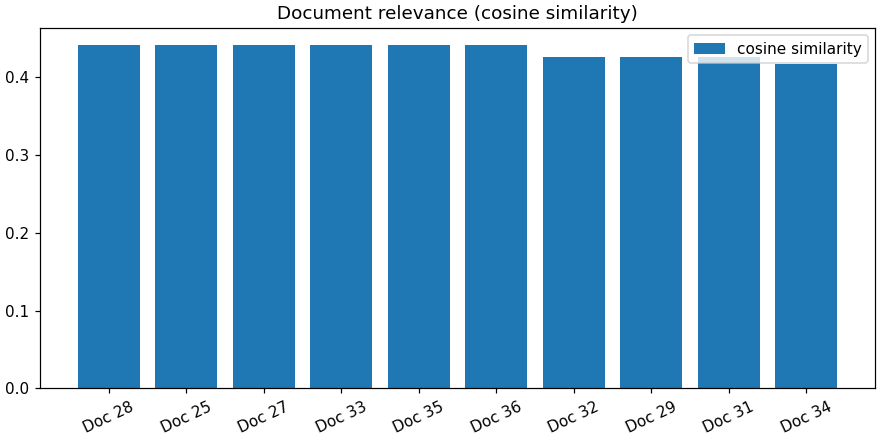

Cosine similarity is lexical relevance, not clinical advice. No relevance judgments or sense labels are supplied, so ranking and sense accuracy are not measured.


In [38]:
data_t12 = tutorial_dataset(12)
result_t12 = run_analysis(12, data_t12, text="Diabetes on metformin 500 mg. MS after neurological assessment.", query="diabetes glucose")
show_analysis(result_t12)


# T13 — Dimensionality reduction for exploratory data analysis in daily medical research

**Objective:** Dimensionality reduction for exploratory data analysis in daily medical research.

**Dataset / source:** Synthetic adult behavioral measurements; locally generated `example_data(13)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `age, height_m, weight_kg, activity_hours_week, sedentary_hours_day, sleep_hours`.  **Target/output:** Exploratory numerical projections.

**Preprocessing and method:** Select adults with known age ≥18, validate units/ranges, median-impute and standardize numeric measurements. Report PCA explained/cumulative variance and 2D coordinates. Compare Isomap neighborhood embedding (at most 500 rows). Exploratory fit uses all observations and does not estimate predictive performance.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T13, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,unknown_age_rows_excluded,adult_rows,first_two_variance
0,0,0,180,0.501473


missing_values


,column,missing
0,age,0
1,height_m,0
2,weight_kg,0
3,activity_hours_week,0
4,sedentary_hours_day,0
5,sleep_hours,0


descriptive


... (6 outputs left out)

,component,variance,cumulative
0,1,0.306563,0.306563
1,2,0.194910,0.501473
2,3,0.178659,0.680132
3,4,0.154360,0.834492
4,5,0.140129,0.974621
5,6,0.025379,1.000000


pca_coordinates


,PC1,PC2
0,-0.130635,0.850584
1,0.119363,0.120097
2,0.265832,0.165843
3,0.508592,1.318367
4,-1.098302,0.564149
5,2.081949,-0.165048
6,-1.708235,0.626706
7,-1.755174,0.482400
8,-1.205326,2.074283
9,0.286909,0.847150


PCA projection


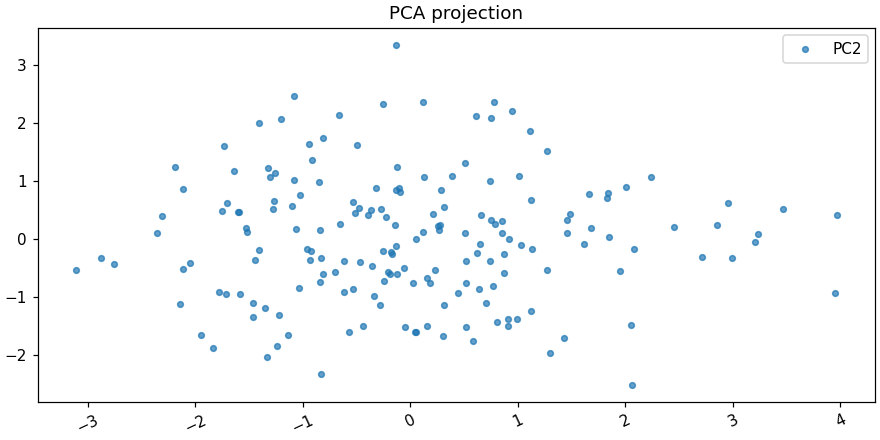

Isomap nonlinear projection (up to 500 rows)


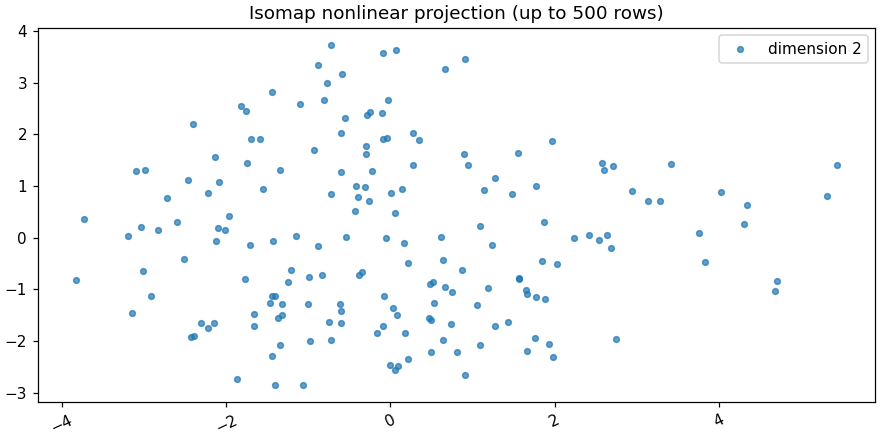

Median imputation and standardization precede PCA. Isomap preserves neighborhood geometry; axes and distances differ from PCA. Projections are exploratory and establish no biological groups.


In [39]:
data_t13 = tutorial_dataset(13)
result_t13 = run_analysis(13, data_t13)
show_analysis(result_t13)


# T14 — Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 1

**Objective:** Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 1.

**Dataset / source:** Synthetic adult behavioral measurements; locally generated `example_data(14)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `age, height_m, weight_kg, activity_hours_week, sedentary_hours_day, sleep_hours`.  **Target/output:** Adult BMI and descriptive associations.

**Preprocessing and method:** Exclude unknown/minor ages. Height is meters, weight kilograms, activity hours/week and sedentary/sleep hours/day. Validate plausible ranges, retain missing values in descriptive counts and compute BMI only for observed height/weight. Inspect IQR flags, distributions and pairwise correlations.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T14, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data

,duplicate_rows_removed,unknown_age_rows_excluded,adult_rows
0,0,0,180


missing_values


,column,missing
0,age,0
1,height_m,0
2,weight_kg,0
3,activity_hours_week,0
4,sedentary_hours_day,0
5,sleep_hours,0


descriptive


... (2 outputs left out)

,index,age,height_m,weight_kg,activity_hours_week,sedentary_hours_day,sleep_hours,BMI
0,age,1.000000,0.093184,0.152031,0.080028,0.026429,-0.048671,0.127170
1,height_m,0.093184,1.000000,0.630517,0.006745,-0.023537,-0.000086,-0.055893
2,weight_kg,0.152031,0.630517,1.000000,-0.362378,0.371434,-0.121410,0.735493
3,activity_hours_week,0.080028,0.006745,-0.362378,1.000000,-0.031799,-0.013148,-0.486160
4,sedentary_hours_day,0.026429,-0.023537,0.371434,-0.031799,1.000000,0.138999,0.501064
5,sleep_hours,-0.048671,-0.000086,-0.121410,-0.013148,0.138999,1.000000,-0.172494
6,BMI,0.127170,-0.055893,0.735493,-0.486160,0.501064,-0.172494,1.000000


outlier_inspection


,feature,IQR_flags
0,age,0
1,height_m,3
2,weight_kg,8
3,activity_hours_week,0
4,sedentary_hours_day,0
5,sleep_hours,0


Physical activity and BMI


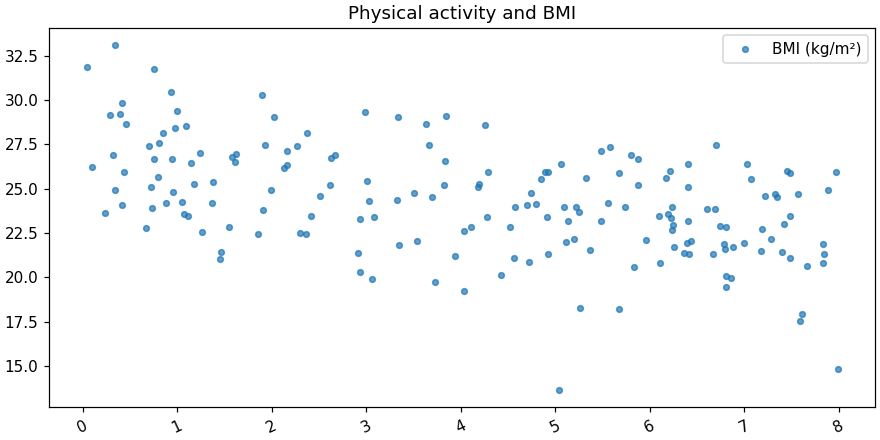

Adult BMI distribution


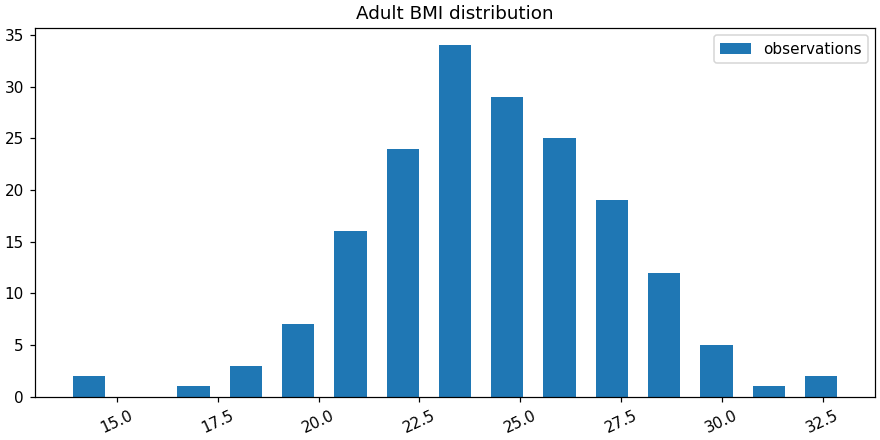

BMI = weight_kg / height_m² only for valid measured values. Adults selected by known age ≥18; IQR flags are inspected, not automatically removed. Associations do not establish causation or justify health recommendations.


In [40]:
data_t14 = tutorial_dataset(14)
result_t14 = run_analysis(14, data_t14)
show_analysis(result_t14)


# T15 — Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 2

**Objective:** Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 2.

**Dataset / source:** Synthetic adult behavioral measurements; locally generated `example_data(15)`, seed 42. This is educational synthetic data with known generator relationships, not observed healthcare evidence. No download is required. For real analyses supply a compatible CSV from your approved public or de-identified source; the application does not independently verify provenance.

**Expected columns:** `age, height_m, weight_kg, activity_hours_week, sedentary_hours_day, sleep_hours`.  **Target/output:** BMI.

**Preprocessing and method:** Use the T14 validation. Random 75/25 holdout; fit median imputation, scaling and regression only on training data. Predict BMI from age/activity/sedentary/sleep (exclude height and weight to avoid target leakage). Report MAE, RMSE, R² and coefficients per training SD. Pearson activity/BMI correlation uses independent pairs and Fisher 95% CI; associations do not establish causation.

**Validation:** Empty inputs, missing required columns and malformed types produce readable errors. View missingness and actual output tables below. T11/T12 descriptive outputs lack labeled benchmarks; metrics are reported only when meaningful.

**Frontend demonstration:** Select T15, optionally download its labeled example CSV, set inputs and click Run analysis. Use the tables, plots and JSON export to inspect computed results.

**Reproduction:** The next cell imports the same computation as the API. Set `csv_path` in `tutorial_dataset` to use available external data. Interpretation is generated from actual results below.


SOURCE: synthetic demonstration, seed 42, not real patient data


Deterministic synthetic demonstration (seed 42); not actual patient data


,duplicate_rows_removed,unknown_age_rows_excluded,adult_rows,MAE,RMSE,R2,train_rows,test_rows,activity_pearson_r,activity_p,correlation_CI_low,correlation_CI_high
0,0,0,180,1.580295,1.942611,0.546946,135,45,-0.48616,4.564457e-12,-0.590439,-0.365916


missing_values


,column,missing
0,age,0
1,height_m,0
2,weight_kg,0
3,activity_hours_week,0
4,sedentary_hours_day,0
5,sleep_hours,0


descriptive


... (4 outputs left out)

,feature,IQR_flags
0,age,0
1,height_m,3
2,weight_kg,8
3,activity_hours_week,0
4,sedentary_hours_day,0
5,sleep_hours,0


coefficients


,feature,BMI_change_per_training_SD
0,age,0.444791
1,activity_hours_week,-1.544848
2,sedentary_hours_day,1.704077
3,sleep_hours,-0.708146


Physical activity and BMI


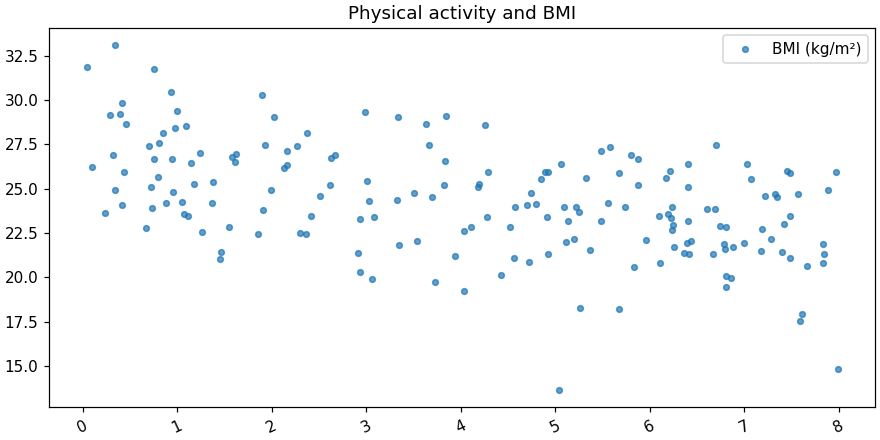

Adult BMI distribution


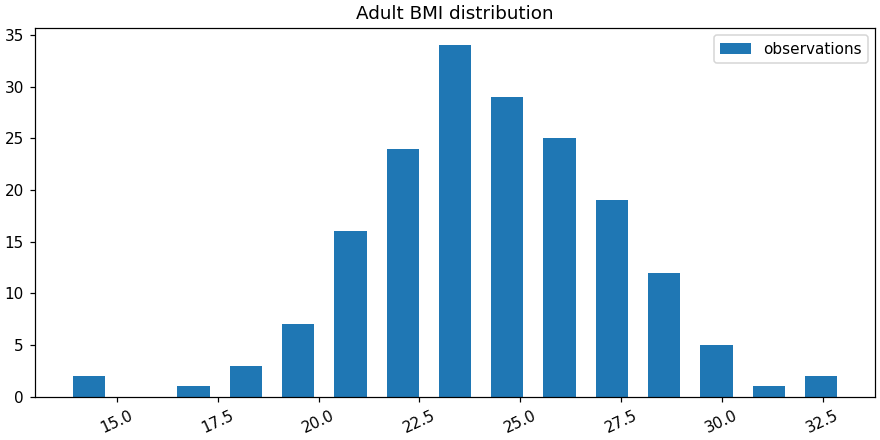

Held-out BMI predictions


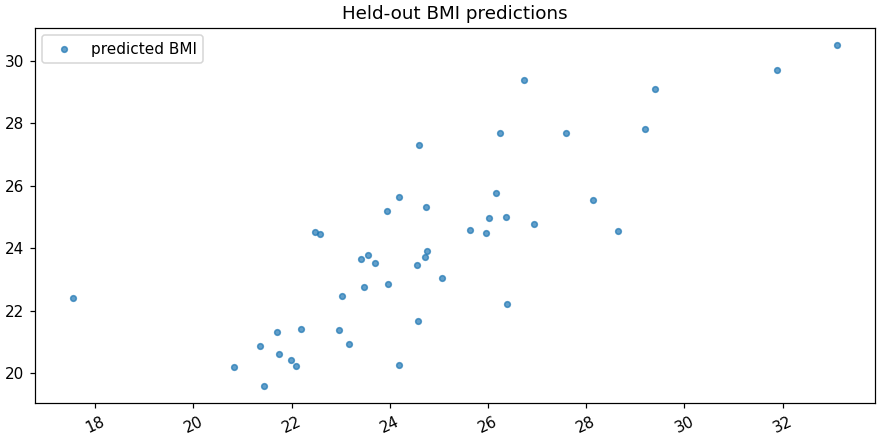

Largest absolute standardized coefficient: sedentary_hours_day. Pearson inference assumes independent observations and an approximately bivariate-normal relationship. Confidence interval uses Fisher transformation.
BMI = weight_kg / height_m² only for valid measured values. Adults selected by known age ≥18; IQR flags are inspected, not automatically removed. Associations do not establish causation or justify health recommendations.


In [41]:
data_t15 = tutorial_dataset(15)
result_t15 = run_analysis(15, data_t15)
show_analysis(result_t15)


# Complete T1–T15 summary

| Tutorial | Practical |
|---|---|
| T1 | Understanding biomedical MRI data |
| T2 | Standardization and data cleaning |
| T3 | Redundant data removal and missing data |
| T4 | Enhancement, restoration, segmentation, compression |
| T5 | SIFT, RANSAC and CNN image analysis |
| T6 | Biomedical image visualization |
| T7 | Patient prediction for improved staffing |
| T8 | Using healthcare data for informed strategic planning — Part 1 |
| T9 | Using healthcare data for informed strategic planning — Part 2 |
| T10 | Classification and clustering of clinical text data |
| T11 | Information extraction and entity recognition of clinical text data |
| T12 | Ranking and word disambiguation of clinical text data |
| T13 | Dimensionality reduction for exploratory data analysis in daily medical research |
| T14 | Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 1 |
| T15 | Analyzing the complexity of behavioral factors influencing WEIGHTS IN ADULTS — Part 2 |

MRI/CNN and all statistical examples are educational. Refer to SUBMISSION_REPORT.md for actual test status and limitations.
